# Initial Fire and Smoke Model Training

This notebook records the initial training of YOLO26-m and the EfficientNet-B0 crop verifier. It builds the dataset, tests the detector and the video alarm pipeline, and exports the initial project artifacts.


## 01. Configuration and working paths

Defines the dataset sources, training settings, and paths for data, checkpoints, and reports.


In [1]:
# ============================== SETTINGS (edit me) ==============================
import os, sys, json, time, shutil, subprocess, glob, importlib, random
from pathlib import Path

TEAM_ID       = "TeamXX"                                   # zip will be TeamXX_Project.zip
TEAM_MEMBERS  = [("Member 1 name", "Roll no. 1"), ("Member 2 name", "Roll no. 2")]
PROJECT_TYPE  = "fire/smoke detection"

QUICK_TEST    = False      # True = small dry run of the whole notebook (~15-20 min). Do it once first!

VOLUME        = os.environ.get("FIRE_VOLUME")   # None = auto-detect the attached volume under /mnt

# ---- data ----
USE_DFIRE, USE_FASDD = True, True
DFIRE_CAP     = None       # D-Fire: ~21.5k images, use all
FASDD_CAP     = 45000      # FASDD_CV: ~95k images -> random subset (positives first) to fit the GPU budget
FASDD_MAX_NEG = 0.35       # max fraction of negatives in the FASDD subset
EXTRA_SOURCES = []         # e.g. [{"name": "lfdn"}] -> put that zip in raw/lfdn/. For YOLO .txt labels without a
                           # names file add "id_map": {0: "fire", 1: "smoke"} (check the picture grid in Step 1!)
MAX_SIDE      = 960        # images are resized so the long side <= this (much faster data loading)

# ---- extra data that is downloaded automatically (you do not need to provide videos) ----
AUTO_STREET_NEGATIVES = True   # Indian CCTV traffic frames (SentinelEdge, CC BY 4.0) as fire-free hard negatives
STREET_NEG_TRAIN  = 2000       # frames added to training as negatives (Bengaluru CCTV + UA-DETRAC)
STREET_NEG_MINING = 800        # other frames: the detector's false alarms on them are mined and trained on (v2)
STREET_NEG_TEST   = 400        # frames from other cameras, only used to measure the false-alarm rate
AUTO_EVAL_VIDEOS  = True       # FIRESENSE (Zenodo, CC BY 4.0): labelled fire / smoke / normal test videos
EVAL_MAX_SECONDS  = 900        # only the first 15 minutes of each test video are used

# ---- detector (A100 80GB) ----
DET_MODEL     = "yolo26m.pt"   # COCO-pretrained YOLO26-m (downloaded automatically)
IMGSZ         = 800          # 640 = faster; 800 sees small / distant fire better
DET_BATCH     = 64
DET_HOURS_V1  = 2.0            # training time budget in hours (Ultralytics fits the LR schedule to it)
DET_HOURS_V2  = 0.75           # fine-tune with mined hard negatives (skipped if there are no normal videos)

# ---- verifier ----
VERIFIER_EPOCHS = 8
VERIFIER_BATCH  = 128

# ---- alarm tuning ----
TUNE_ALARMS   = True           # grid-search the temporal settings on raw/eval_videos (if present)
RUN_FRESH_ENV_TEST = True      # Step 6: install requirements.txt in a new venv and run the zip offline

if QUICK_TEST:
    DFIRE_CAP, FASDD_CAP = 1500, 1500
    DET_MODEL, DET_HOURS_V1, DET_HOURS_V2 = "yolo26n.pt", 0.05, 0.03
    VERIFIER_EPOCHS = 1
    STREET_NEG_TRAIN, STREET_NEG_MINING, STREET_NEG_TEST = 60, 40, 30
    EVAL_MAX_SECONDS = 60

# (only used for local testing of this notebook)
globals().update(json.loads(os.environ.get("FIRE_OVERRIDES", "{}")))

# ---- paths ----
if VOLUME is None:
    if Path("/root/lab/volume").exists():          # `modal launch jupyter --volume <name>` mounts the volume here
        VOLUME = "/root/lab/volume"
    else:
        mnts = sorted(p for p in Path("/mnt").iterdir() if p.is_dir()) if Path("/mnt").exists() else []
        if len(mnts) == 1:
            VOLUME = str(mnts[0])
        else:
            VOLUME = str(Path.home() / "fire-vol")
            print(f"WARNING: no persistent volume found - using {VOLUME}, which is NOT kept when the session stops. "
                  "Set VOLUME = '/path/to/volume' above if you have one.")
VOL         = Path(VOLUME)
SFX         = "_quick" if QUICK_TEST else ""
PROJECT_DIR = VOL / "fire_project"                         # code + weights + config (= the submission)
RAW_DIR     = VOL / "raw"                                  # downloads + your own videos/images
RUNS_DIR    = VOL / "runs"                                 # training runs / checkpoints
CACHE_DIR   = VOL / "cache"                                # dataset tar for fast restore
WORK_DIR    = Path(os.environ.get("FIRE_WORK", "/root/work"))   # fast local (ephemeral) disk
DATASET_DIR = WORK_DIR / f"dataset{SFX}"
DATASET_TAR = CACHE_DIR / f"dataset{SFX}.tar"
CROPS_DIR   = WORK_DIR / f"verifier_crops{SFX}"
EVAL_DIR    = RAW_DIR / "eval_videos"
for d in [PROJECT_DIR / "firedet", PROJECT_DIR / "scripts", PROJECT_DIR / "weights", PROJECT_DIR / "reports",
          RAW_DIR / "normal_videos", RAW_DIR / "negatives", EVAL_DIR / "fire", EVAL_DIR / "smoke", EVAL_DIR / "normal",
          RUNS_DIR, CACHE_DIR, WORK_DIR]:
    d.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_DIR)
print("volume :", VOL)
print("project:", PROJECT_DIR, "| work (local disk):", WORK_DIR, "| QUICK_TEST:", QUICK_TEST)

volume : /root/lab/volume
project: /root/lab/volume/fire_project | work (local disk): /root/work | QUICK_TEST: False


## 02. Kernel check

Records a simple check that the Python kernel is responding.


In [2]:
print("ok")

ok


## 03. Python dependencies

Installs the training dependencies and records the available package versions.


In [3]:
!pip install -q "ultralytics==8.4.194" "imagehash==4.3.2" "huggingface_hub>=0.24" "pyarrow>=15" requests pandas
try:
    import cv2
except ImportError as e:      # minimal images miss libGL -> use the headless OpenCV build
    print("OpenCV import failed:", e, "-> switching to opencv-python-headless")
    !pip uninstall -y -q opencv-python opencv-python-headless
    !pip install -q opencv-python-headless
    import cv2
import torch, torchvision, ultralytics
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| ultralytics", ultralytics.__version__,
      "| opencv", cv2.__version__)


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
OpenCV import failed: libxcb.so.1: cannot open shared object file: No such file or directory -> switching to opencv-python-headless

[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
torch 2.15.0+cu132 | torchvision 0.29.2+cu132 | ultralytics 8.4.194 | opencv 5.0.0


## 04. Hardware check

Reports GPU, CPU, disk, and shared-memory availability and sets the data-loader worker count.


In [4]:
import torch, shutil, os
CPUS = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
try:   # containers: the CPU quota can be lower than the visible cores
    q, per = open("/sys/fs/cgroup/cpu.max").read().split()
    if q != "max":
        CPUS = max(1, min(CPUS, int(int(q) / int(per))))
except Exception:
    pass
WORKERS = max(2, min(16, CPUS - 1))
DEVICE = 0 if torch.cuda.is_available() else "cpu"
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}  {p.total_memory / 1e9:.0f} GB")
else:
    print("No GPU (fine for Step 1 data preparation; switch to the A100 profile for training)")
print(f"CPU cores: {CPUS} -> data-loader workers: {WORKERS}")
for d in (WORK_DIR, VOL):
    t, u, f = shutil.disk_usage(d)
    print(f"disk {d}: {f / 1e9:.0f} GB free of {t / 1e9:.0f} GB")
try:
    shm = shutil.disk_usage("/dev/shm").total / 1e9
    print(f"/dev/shm: {shm:.1f} GB")
    if shm < 2:
        WORKERS = min(WORKERS, 4)
        print("WARNING: small shared memory - data-loader workers limited to 4")
except Exception:
    pass
if CPUS < 8:
    print("WARNING: few CPU cores - the GPU will wait for data. Pick a compute profile with 16+ CPUs.")

GPU: NVIDIA A100-SXM4-80GB  85 GB
CPU cores: 32 -> data-loader workers: 16
disk /root/work: 9223372027 GB free of 9223372037 GB
disk /root/lab/volume: 410 GB free of 410 GB
/dev/shm: 1010.0 GB


## 05. System certificates

Installs and refreshes the system certificates used for HTTPS downloads.


In [5]:
!apt-get update -qq && apt-get install -y -qq ca-certificates && update-ca-certificates

Updating certificates in /etc/ssl/certs...
0 added, 0 removed; done.
Running hooks in /etc/ca-certificates/update.d...
done.


## 06. Package initialization

Writes the `firedet` package initializer.


In [6]:
%%writefile firedet/__init__.py
"""firedet: fire/smoke detection with a detector, a crop verifier and temporal alarm logic."""
__version__ = "1.0.0"

Overwriting firedet/__init__.py


## 07. Shared utilities

Writes utilities for labels, configuration, frame handling, crops, and box geometry.


In [7]:
%%writefile firedet/common.py
"""Shared helpers: constants, config loading, crop extraction, timing."""
import math
import os
import random
import time
from pathlib import Path

import numpy as np
import yaml

CLASS_NAMES = ["fire", "smoke"]          # final detector class ids: 0 = fire, 1 = smoke
EVENT_LABELS = ("fire", "smoke")
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
VID_EXTS = {".mp4", ".avi", ".mov", ".mkv", ".m4v", ".mpg", ".mpeg", ".wmv", ".webm", ".3gp", ".ts"}

# Names found in other datasets that we map onto our two classes. Anything else is dropped.
LABEL_ALIASES = {
    "fire": "fire", "flame": "fire", "flames": "fire", "fire_flame": "fire", "burning": "fire",
    "smoke": "smoke", "smokes": "smoke", "fumes": "smoke",
}


def load_yaml(path):
    with open(path, "r", encoding="utf-8") as f:
        return yaml.safe_load(f) or {}


def save_yaml(data, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        yaml.safe_dump(data, f, sort_keys=False, allow_unicode=True)


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
    except Exception:
        pass


def fmt_secs(s):
    s = int(max(0, s))
    h, r = divmod(s, 3600)
    m, s = divmod(r, 60)
    return f"{h:d}h{m:02d}m{s:02d}s" if h else f"{m:d}m{s:02d}s"


def resolve_path(p, base_dir):
    """Paths in config.yaml are relative to the config file's folder."""
    if p is None:
        return None
    p = Path(os.path.expanduser(str(p)))
    return p if p.is_absolute() else (Path(base_dir) / p).resolve()


def list_files(root, exts):
    root = Path(root)
    if not root.exists():
        return []
    return sorted(p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in exts
                  and "__MACOSX" not in p.parts and not p.name.startswith("._"))


def square_crop(img, box, pad=0.3, min_side=16):
    """Square crop centred on box (x1,y1,x2,y2 in pixels) with `pad` context on each side.
    Out-of-image areas are filled by edge replication. Identical at training and inference."""
    h, w = img.shape[:2]
    x1, y1, x2, y2 = [float(v) for v in box]
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    side = max(x2 - x1, y2 - y1, 1.0) * (1 + 2 * pad)
    side = max(side, min_side)
    half = side / 2
    a, b = int(math.floor(cx - half)), int(math.floor(cy - half))
    c, d = int(math.ceil(cx + half)), int(math.ceil(cy + half))
    pl, pt, pr, pb = max(0, -a), max(0, -b), max(0, c - w), max(0, d - h)
    crop = img[max(0, b):min(h, d), max(0, a):min(w, c)]
    if crop.size == 0:
        return None
    if pl or pt or pr or pb:
        import cv2
        crop = cv2.copyMakeBorder(crop, pt, pb, pl, pr, cv2.BORDER_REPLICATE)
    return crop


def box_iou(a, b):
    """IoU between arrays of boxes a (N,4) and b (M,4) in xyxy -> (N,M)."""
    a = np.asarray(a, dtype=np.float32).reshape(-1, 4)
    b = np.asarray(b, dtype=np.float32).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), dtype=np.float32)
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0])
    iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2])
    iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / np.clip(area_a[:, None] + area_b[None, :] - inter, 1e-9, None)


def read_yolo_label(path, w=1.0, h=1.0):
    """Read a YOLO label file -> (classes list, boxes xyxy scaled by w,h)."""
    cls, boxes = [], []
    p = Path(path)
    if not p.exists():
        return cls, np.zeros((0, 4), dtype=np.float32)
    for line in p.read_text().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue
        c, cx, cy, bw, bh = int(float(parts[0])), *map(float, parts[1:5])
        cls.append(c)
        boxes.append([(cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h])
    return cls, np.asarray(boxes, dtype=np.float32).reshape(-1, 4)


class Timer:
    def __init__(self):
        self.t0 = time.time()

    def elapsed(self):
        return time.time() - self.t0

Overwriting firedet/common.py


## 08. Dataset preparation module

Writes code to fetch the sources, convert labels, remove duplicates, and build the dataset splits.


In [8]:
%%writefile firedet/data_prep.py
"""Dataset download, conversion, de-duplication and splitting.

Output: one YOLO dataset with classes 0 = fire, 1 = smoke:
    <out>/images/{train,val,test}/*.jpg   <out>/labels/{train,val,test}/*.txt   <out>/data.yaml
Every source is converted to the same class ids, images are resized (long side <= max_side),
exact and near duplicates are removed (perceptual hash), and near-duplicate / consecutive-frame
groups are kept inside one split so validation is not inflated by leakage.
"""
import base64
import csv
import json
import os
import random
import re
import shutil
import tarfile
import time
import xml.etree.ElementTree as ET
import zipfile
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from multiprocessing import Pool
from pathlib import Path

import numpy as np

from .common import CLASS_NAMES, IMG_EXTS, LABEL_ALIASES, VID_EXTS, fmt_secs, list_files, save_yaml

DFIRE_ID_MAP = {0: "smoke", 1: "fire"}   # D-Fire: 0 = smoke, 1 = fire (opposite of ours!)
FASDD_ID_MAP = {0: "fire", 1: "smoke"}   # FASDD: 0 = fire, 1 = smoke


# --------------------------------------------------------------------------------------- downloads
def _retry(fn, tries=6, base=5, what=""):
    for i in range(tries):
        try:
            return fn()
        except Exception as e:  # noqa: BLE001
            if i == tries - 1:
                raise
            wait = base * 2 ** i
            print(f"   {what}: attempt {i + 1}/{tries} failed ({type(e).__name__}: {str(e)[:120]}) - retry in {wait}s")
            time.sleep(wait)


def hf_list(repo_id):
    from huggingface_hub import HfApi
    return _retry(lambda: HfApi().list_repo_files(repo_id, repo_type="dataset"), what=f"list {repo_id}")


def hf_get(repo_id, filename, dest_dir):
    from huggingface_hub import hf_hub_download
    return _retry(lambda: hf_hub_download(repo_id, filename, repo_type="dataset", local_dir=str(dest_dir)),
                  what=f"{repo_id}/{filename}")


def url_get(url, dest):
    import requests
    dest = Path(dest)
    dest.parent.mkdir(parents=True, exist_ok=True)

    def _go():
        with requests.get(url, stream=True, timeout=60, allow_redirects=True) as r:
            r.raise_for_status()
            tmp = dest.with_suffix(dest.suffix + ".part")
            with open(tmp, "wb") as f:
                for chunk in r.iter_content(1 << 22):
                    f.write(chunk)
            tmp.rename(dest)
        return dest
    return _retry(_go, tries=3, what=url[:60])


def onedrive_direct(share_url):
    """Public OneDrive share link -> direct download URL."""
    b64 = base64.urlsafe_b64encode(share_url.encode()).decode().rstrip("=")
    return f"https://api.onedrive.com/v1.0/shares/u!{b64}/root/content"


def extract_archive(path, out_dir):
    """Extract zip/tar once (a marker file makes re-runs instant)."""
    path, out_dir = Path(path), Path(out_dir)
    marker = out_dir / f".extracted_{path.name}"
    if marker.exists():
        return out_dir
    out_dir.mkdir(parents=True, exist_ok=True)
    print(f"   extracting {path.name} ({path.stat().st_size / 1e9:.2f} GB) -> {out_dir}")
    if zipfile.is_zipfile(path):
        with zipfile.ZipFile(path) as z:
            z.extractall(out_dir)
    elif tarfile.is_tarfile(path):
        with tarfile.open(path) as t:
            t.extractall(out_dir)
    else:
        raise ValueError(f"not a zip/tar archive: {path}")
    marker.touch()
    return out_dir


def _manual_drop(raw_dir, name, extract_dir):
    """If the user put a zip/tar or an unpacked folder in raw/<name>/, use it."""
    d = Path(raw_dir) / name
    if not d.exists():
        return None
    archives = [p for p in d.iterdir() if p.is_file() and (p.suffix.lower() in {".zip", ".tar", ".gz", ".tgz"})]
    for a in archives:
        extract_archive(a, Path(extract_dir) / name)
    if archives:
        return Path(extract_dir) / name
    if list_files(d, IMG_EXTS)[:1]:
        return d
    return None


def _parquet_to_yolo(parquet_files, out_dir):
    """HF parquet export (image bytes + YOLO label text) -> images/ + labels/ folders."""
    import pyarrow.parquet as pq
    out_dir = Path(out_dir)
    if (out_dir / ".done").exists():
        return out_dir
    (out_dir / "images").mkdir(parents=True, exist_ok=True)
    (out_dir / "labels").mkdir(parents=True, exist_ok=True)
    n = 0
    for pf in parquet_files:
        f = pq.ParquetFile(pf)
        cols = f.schema_arrow.names
        img_col = next((c for c in cols if "image" in c.lower()), None)
        lab_col = next((c for c in cols if c.lower() in {"label", "labels", "annotation", "annotations", "txt"}), None)
        fn_col = next((c for c in cols if c.lower() in {"filename", "file_name", "name", "path", "image_id"}), None)
        if img_col is None or lab_col is None:
            raise ValueError(f"unexpected parquet columns {cols}")
        for batch in f.iter_batches(batch_size=256):
            d = batch.to_pydict()
            for i, img in enumerate(d[img_col]):
                raw = img.get("bytes") if isinstance(img, dict) else img
                if not raw:
                    continue
                lab = d[lab_col][i]
                if lab is not None and not isinstance(lab, str):
                    raise ValueError("label column is not YOLO text")
                fn = d[fn_col][i] if fn_col else (img.get("path") if isinstance(img, dict) else None)
                stem = Path(str(fn)).stem if fn else f"img_{n:07d}"
                (out_dir / "images" / f"{stem}.jpg").write_bytes(raw)
                (out_dir / "labels" / f"{stem}.txt").write_text(lab or "")
                n += 1
    (out_dir / ".done").touch()
    print(f"   parquet -> {n:,} images")
    return out_dir


DFIRE_ONEDRIVE = "https://1drv.ms/u/c/c0bd25b6b048b01d/EbLgD7bES4FDvUN37Grxn8QBF5gIBBc7YV2qklF08GCiBw"
DFIRE_HF_PARQUET = ["badsaarow/d-fire"]                 # Hugging Face mirrors, tried in this order; each is CHECKED after download
DFIRE_HF_ZIP = ["Stevebirth/fire-ulm-dfire"]
FASDD_HF_REPOS = ["weslleyskah/fire_smoke_dataset_fasdd_cv", "seawsurf/fire_smoke_dataset_fasdd_cv"]
SENTINEL_REPO = "kalyan1729/sentineledgedataset"         # Bengaluru CCTV + UA-DETRAC traffic frames (CC BY 4.0): fire-free negatives
FIRESENSE_URLS = {"fire": "https://zenodo.org/records/836749/files/fire_videos.1406.zip?download=1",
                  "smoke": "https://zenodo.org/records/836749/files/smoke_videos.1407.zip?download=1"}


def _nums(vals):
    try:
        for v in vals:
            float(v)
        return True
    except ValueError:
        return False


def yolo_folder_ok(root, min_pos_frac=0.2, sample=400, seed=0):
    """Sanity check of a downloaded folder: do its .txt files hold valid 'class cx cy w h' lines?
    Guards against mirrors whose label column is something else (then the next source is tried)."""
    lbls = [p for p in Path(root).rglob("*.txt") if p.stem.lower() not in SKIP_TXT]
    if len(lbls) < 50:
        return False
    random.Random(seed).shuffle(lbls)
    lbls = lbls[:sample]
    pos = bad = 0
    for p in lbls:
        try:
            rows = [l.split() for l in p.read_text(errors="ignore").splitlines() if l.strip()]
        except Exception:  # noqa: BLE001
            bad += 1
            continue
        if not rows:
            continue
        good = all(len(r) >= 5 and _nums(r[:5]) and 0 <= float(r[1]) <= 1 and 0 <= float(r[2]) <= 1
                   and 0 < float(r[3]) <= 1 and 0 < float(r[4]) <= 1 for r in rows)
        pos += int(good)
        bad += int(not good)
    return bad <= 0.05 * len(lbls) and pos >= min_pos_frac * len(lbls)


def get_dfire(raw_dir, extract_dir):
    """Returns a folder containing D-Fire images + YOLO labels (0=smoke, 1=fire), or None."""
    raw_dir, extract_dir = Path(raw_dir), Path(extract_dir)
    p = _manual_drop(raw_dir, "dfire", extract_dir)
    if p:
        print("D-Fire: using files you placed in raw/dfire/")
        return p
    for repo in DFIRE_HF_PARQUET:          # 1) Hugging Face parquet mirror
        try:
            files = [f for f in hf_list(repo) if f.endswith(".parquet")]
            if not files:
                raise RuntimeError("no parquet files")
            print(f"D-Fire: downloading {len(files)} parquet files from HF {repo}")
            local = [hf_get(repo, f, raw_dir / "dfire_hf_parquet") for f in files]
            out = _parquet_to_yolo(local, extract_dir / "dfire_parquet")
            if yolo_folder_ok(out):
                return out
            print(f"D-Fire: {repo} does not contain usable YOLO labels - trying the next source")
        except Exception as e:  # noqa: BLE001
            print(f"D-Fire: {repo} failed ({str(e)[:150]})")
    for repo in DFIRE_HF_ZIP:              # 2) Hugging Face zip mirror
        try:
            zips = [f for f in hf_list(repo) if f.lower().endswith(".zip")]
            if not zips:
                raise RuntimeError("no zip")
            print(f"D-Fire: downloading {zips} from HF {repo}")
            for z in zips:
                extract_archive(hf_get(repo, z, raw_dir / "dfire_hf_zip"), extract_dir / "dfire_zip")
            if yolo_folder_ok(extract_dir / "dfire_zip"):
                return extract_dir / "dfire_zip"
            print(f"D-Fire: {repo} does not contain usable YOLO labels - trying the next source")
        except Exception as e:  # noqa: BLE001
            print(f"D-Fire: {repo} failed ({str(e)[:150]})")
    try:                                   # 3) official OneDrive link
        dest = raw_dir / "dfire_onedrive" / "D-Fire.zip"
        if not dest.exists():
            print("D-Fire: downloading from the official OneDrive link")
            url_get(onedrive_direct(DFIRE_ONEDRIVE), dest)
        out = extract_archive(dest, extract_dir / "dfire_onedrive")
        if yolo_folder_ok(out):
            return out
        print("D-Fire: the OneDrive archive has no usable YOLO labels")
    except Exception as e:  # noqa: BLE001
        print(f"D-Fire: OneDrive failed ({str(e)[:150]})")
    print("D-Fire: ALL automatic downloads failed. Download it yourself from "
          "https://github.com/gaia-solutions-on-demand/DFireDataset and put the zip in raw/dfire/, then re-run.")
    return None


def get_fasdd(raw_dir, extract_dir):
    raw_dir, extract_dir = Path(raw_dir), Path(extract_dir)
    p = _manual_drop(raw_dir, "fasdd", extract_dir)
    if p:
        print("FASDD: using files you placed in raw/fasdd/")
        return p
    for repo in FASDD_HF_REPOS:
        owner = repo.split("/")[0]
        try:
            files = hf_list(repo)
            arch = [f for f in files if f.lower().endswith((".zip", ".tar", ".tar.gz", ".tgz"))]
            parq = [f for f in files if f.endswith(".parquet")]
            if arch:
                print(f"FASDD: downloading {arch} from HF {repo}")
                for z in arch:
                    extract_archive(hf_get(repo, z, raw_dir / "fasdd_hf" / owner), extract_dir / "fasdd" / owner)
                root = extract_dir / "fasdd" / owner
            elif parq:
                print(f"FASDD: downloading {len(parq)} parquet files from HF {repo}")
                local = [hf_get(repo, f, raw_dir / "fasdd_hf" / owner) for f in parq]
                root = _parquet_to_yolo(local, extract_dir / "fasdd" / owner)
            else:
                from huggingface_hub import snapshot_download
                print(f"FASDD: downloading {len(files)} files from HF {repo} (a few GB)")
                root = Path(_retry(lambda: snapshot_download(repo, repo_type="dataset", local_dir=str(raw_dir / "fasdd_hf" / owner),
                                                              max_workers=16), what=repo))
            if yolo_folder_ok(root) or list(Path(root).rglob("*.xml"))[:1]:
                return root
            print(f"FASDD: {repo} does not contain usable labels - trying the next source")
        except Exception as e:  # noqa: BLE001
            print(f"FASDD: {repo} failed ({str(e)[:150]})")
    print("FASDD: not available. Optional - download FASDD_CV from Science Data Bank "
          "(https://doi.org/10.57760/sciencedb.j00104.00103) and put the zip in raw/fasdd/.")
    return None


def _hf_download_retry(repo, filename, local_dir, tries=3):
    from huggingface_hub import hf_hub_download
    for i in range(tries):
        try:
            return hf_hub_download(repo, filename, repo_type="dataset", local_dir=str(local_dir))
        except Exception:  # noqa: BLE001
            if i == tries - 1:
                return None
            time.sleep(2 * 2 ** i)


def get_street_frames(raw_dir, n_train=2000, n_mine=800, n_test=400, seed=0, workers=16, max_side=960):
    """Fire-free CCTV traffic frames from the SentinelEdge dataset (Hugging Face, CC BY 4.0).
      train: Bengaluru CCTV (BMD-45) + UA-DETRAC  -> hard negatives for training
      mine : Bengaluru UVH-26 folders 000-001     -> the detector's false alarms on them are mined (detector v2)
      test : UVH-26 folder 002 + IITM-HeTra       -> other cameras, only used to measure the false-alarm rate
    Frames are saved as JPEGs with the long side <= max_side. Returns {bucket: folder} for the buckets that are available."""
    import cv2
    raw_dir = Path(raw_dir)
    base = raw_dir / "street_frames"
    plan = {"train": ([("BMD-45-Train/", 0.65), ("DETRAC/DETRAC-Images/", 0.35)], n_train),
            "mine": ([("UVH-26-Train/data/000/", 0.5), ("UVH-26-Train/data/001/", 0.5)], n_mine),
            "test": ([("UVH-26-Train/data/002/", 0.6), ("IITM-HeTra_v2/", 0.4)], n_test)}

    def available():
        return {k: base / k for k in plan if (base / k / ".done").exists() and len(list_files(base / k, IMG_EXTS)) >= 20}

    if len(available()) == len(plan) or not any(n for _, n in plan.values()):
        return available()
    try:
        files = hf_list(SENTINEL_REPO)
    except Exception as e:  # noqa: BLE001
        print(f"street frames: cannot list {SENTINEL_REPO} ({str(e)[:120]}) - skipped (the notebook still runs without them)")
        return available()
    rng = random.Random(seed)
    img_ext = {".png", ".jpg", ".jpeg"}
    jobs = []
    for bucket, (parts, n) in plan.items():
        if (base / bucket / ".done").exists():
            continue
        for prefix, frac in parts:
            cand = [f for f in files if f.startswith(prefix) and Path(f).suffix.lower() in img_ext]
            if not cand:
                print(f"street frames: nothing found under {prefix} - that part is skipped")
                continue
            rng.shuffle(cand)
            jobs += [(bucket, f) for f in cand[:int(n * frac)]]
    print(f"street frames: downloading {len(jobs):,} frames from {SENTINEL_REPO} ...")
    tmp = base / "_tmp"
    stats = Counter()
    t0 = time.time()

    def work(job):
        bucket, f = job
        dest = base / bucket / f"{Path(f).parent.name}__{Path(f).stem}.jpg"
        if dest.exists():
            return bucket, True
        p = _hf_download_retry(SENTINEL_REPO, f, tmp)
        if p is None:
            return bucket, False
        try:
            img = cv2.imdecode(np.fromfile(p, dtype=np.uint8), cv2.IMREAD_COLOR)
            if img is None:
                return bucket, False
            dest.parent.mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(dest), _resize(img, max_side), [cv2.IMWRITE_JPEG_QUALITY, 92])
            return bucket, True
        except Exception:  # noqa: BLE001
            return bucket, False
        finally:
            try:
                os.remove(p)
            except OSError:
                pass

    done = 0
    with ThreadPoolExecutor(workers) as ex:
        for bucket, ok in ex.map(work, jobs):
            stats[(bucket, ok)] += 1
            done += 1
            if done % 500 == 0 or done == len(jobs):
                el = time.time() - t0
                print(f"   street frames: {done:,}/{len(jobs):,} elapsed {fmt_secs(el)} ETA {fmt_secs(el / done * (len(jobs) - done))}")
    shutil.rmtree(tmp, ignore_errors=True)
    for bucket in plan:
        ok_n, bad_n = stats[(bucket, True)], stats[(bucket, False)]
        if ok_n >= 20 and ok_n >= 0.7 * (ok_n + bad_n):
            (base / bucket).mkdir(parents=True, exist_ok=True)
            (base / bucket / ".done").touch()
        if ok_n or bad_n:
            print(f"   {bucket}: {ok_n:,} frames ok, {bad_n:,} failed")
    return available()


def _firesense_label(rel_parts):
    """FIRESENSE file/folder names -> 'event' (positive), 'normal' (negative) or None (cannot tell)."""
    s = "/".join(rel_parts).lower()
    toks = {t for t in re.split(r"[^a-z]+", s) if t}
    if (toks & {"neg", "negative", "negatives", "normal", "nonfire", "nofire", "nosmoke", "nonsmoke", "false"}
            or "non" in toks or ("no" in toks and toks & {"fire", "smoke", "flame"})):
        return "normal"
    if toks & {"pos", "positive", "positives"}:
        return "event"
    return None


def get_firesense(raw_dir, eval_dir):
    """FIRESENSE test videos (Zenodo 836749, CC BY 4.0) -> eval_dir/{fire,smoke,normal}/.
    Positive / negative videos are told apart by their file and folder names; if that is not possible the
    videos are skipped (and you can sort them by hand). Returns the number of videos copied per folder."""
    raw_dir, eval_dir = Path(raw_dir), Path(eval_dir)
    marker = eval_dir / ".firesense_done"
    if marker.exists():
        return json.loads(marker.read_text())
    counts = {"fire": 0, "smoke": 0, "normal": 0}
    for kind, url in FIRESENSE_URLS.items():
        try:
            dest = raw_dir / "firesense" / f"{kind}_videos.zip"
            if not dest.exists():
                print(f"FIRESENSE: downloading the {kind} videos from Zenodo ...")
                url_get(url, dest)
            root = extract_archive(dest, raw_dir / "firesense" / f"{kind}_extracted")
        except Exception as e:  # noqa: BLE001
            print(f"FIRESENSE {kind}: download failed ({str(e)[:150]}) - skipped, it is retried on the next run")
            return counts
        vids = list_files(root, VID_EXTS)
        lab = [(v, _firesense_label(v.relative_to(root).parts)) for v in vids]
        pos = [v for v, l in lab if l == "event"]
        neg = [v for v, l in lab if l == "normal"]
        unk = [v for v, l in lab if l is None]
        print(f"FIRESENSE {kind}: {len(vids)} videos -> {len(pos)} with {kind}, {len(neg)} without, {len(unk)} not recognised "
              f"(e.g. {[str(v.relative_to(root)) for v in vids[:3]]})")
        if len(pos) < 3 or len(neg) < 3 or len(unk) > 0.2 * max(1, len(vids)):
            print(f"   cannot tell the positive from the negative {kind} videos by name -> not used. "
                  f"Sort them by hand into raw/eval_videos/{kind}/ and raw/eval_videos/normal/ (they are in {root}).")
            continue
        for sub in (kind, "normal"):
            (eval_dir / sub).mkdir(parents=True, exist_ok=True)
        for v in pos:
            shutil.copy(v, eval_dir / kind / f"fs_{kind}_{v.name}")
            counts[kind] += 1
        for v in neg:
            shutil.copy(v, eval_dir / "normal" / f"fs_{kind}_{v.name}")
            counts["normal"] += 1
    if sum(counts.values()):
        marker.write_text(json.dumps(counts))
    print("FIRESENSE test videos:", counts)
    return counts


# --------------------------------------------------------------------------------------- ingestion
def _names_from_folder(root):
    """Find class names for YOLO txt labels (data.yaml / classes.txt / obj.names)."""
    import yaml
    for p in list(Path(root).rglob("data.yaml")) + list(Path(root).rglob("*.yaml")):
        try:
            d = yaml.safe_load(p.read_text())
            names = d.get("names") if isinstance(d, dict) else None
            if isinstance(names, dict):
                return {int(k): str(v) for k, v in names.items()}
            if isinstance(names, list):
                return dict(enumerate(map(str, names)))
        except Exception:  # noqa: BLE001
            continue
    for nm in ("classes.txt", "obj.names", "_darknet.labels"):
        for p in Path(root).rglob(nm):
            lines = [x.strip() for x in p.read_text().splitlines() if x.strip()]
            if lines:
                return dict(enumerate(lines))
    return None


def _id_map_for(root, default, name):
    """Class ids of a downloaded dataset: read from its own data.yaml / classes file when it names fire AND smoke,
    otherwise the documented default for that dataset."""
    names = _names_from_folder(root)
    if names and {_canon(v) for v in names.values()} >= {"fire", "smoke"}:
        print(f"[{name}] class names from dataset files: {names}")
        return names
    return default


def _canon(name):
    return LABEL_ALIASES.get(str(name).strip().lower().replace(" ", "_").replace("-", "_"))


def _parse_voc(xml_path):
    root = ET.parse(xml_path).getroot()
    size = root.find("size")
    wh = None
    if size is not None:
        try:
            wh = (float(size.findtext("width")), float(size.findtext("height")))
            if wh[0] <= 1 or wh[1] <= 1:
                wh = None
        except (TypeError, ValueError):
            wh = None
    objs = []
    for o in root.iter("object"):
        c = _canon(o.findtext("name", ""))
        bb = o.find("bndbox")
        if c is None or bb is None:
            continue
        try:
            objs.append((c, float(bb.findtext("xmin")), float(bb.findtext("ymin")),
                         float(bb.findtext("xmax")), float(bb.findtext("ymax"))))
        except (TypeError, ValueError):
            continue
    return objs, wh


def _parse_yolo(txt_path, id_map):
    objs = []
    for line in Path(txt_path).read_text(errors="ignore").splitlines():
        p = line.split()
        if len(p) < 5:
            continue
        try:
            cid, cx, cy, w, h = int(float(p[0])), float(p[1]), float(p[2]), float(p[3]), float(p[4])
        except ValueError:
            continue
        c = _canon(id_map.get(cid, "")) if id_map else None
        if c is None:
            continue
        objs.append((c, cx, cy, w, h))
    return objs


SKIP_TXT = {"train", "val", "valid", "test", "classes", "obj", "readme", "license", "labels", "notes"}


def ingest_folder(name, root, id_map=None, cap=None, max_neg_frac=None, seed=0, negatives_only=False,
                  force_split=None, group_fn=None):
    """Turn any image folder (YOLO txt or VOC xml labels) into records.

    record = dict(src, path, fmt('yolo'|'voc'|'neg'), objs, wh, group, force_split)
    """
    root = Path(root)
    imgs = list_files(root, IMG_EXTS)
    if not imgs:
        print(f"[{name}] no images found under {root}")
        return []
    recs = []
    if negatives_only:
        for p in imgs:
            recs.append(dict(src=name, path=str(p), fmt="neg", objs=[], wh=None,
                             group=group_fn(p) if group_fn else None, force_split=force_split))
        print(f"[{name}] {len(recs):,} negative images")
        return _cap(recs, cap, max_neg_frac, seed, name)

    txt_index, xml_index = defaultdict(list), defaultdict(list)
    for p in root.rglob("*.txt"):
        if p.stem.lower() not in SKIP_TXT:
            txt_index[p.stem].append(p)
    for p in root.rglob("*.xml"):
        xml_index[p.stem].append(p)
    if id_map is None and txt_index:
        names = _names_from_folder(root)
        if names:
            id_map = names
            print(f"[{name}] class names from dataset files: {names}")
    missing, bad = 0, 0
    for p in imgs:
        rec = dict(src=name, path=str(p), fmt=None, objs=[], wh=None,
                   group=group_fn(p) if group_fn else None, force_split=force_split)
        # 1) YOLO sibling .../images/x.jpg -> .../labels/x.txt
        parts = list(p.parts)
        sib = None
        if "images" in parts:
            i = len(parts) - 1 - parts[::-1].index("images")
            sib = Path(*parts[:i], "labels", *parts[i + 1:]).with_suffix(".txt")
        try:
            if sib is not None and sib.exists() and id_map:
                rec.update(fmt="yolo", objs=_parse_yolo(sib, id_map))
            elif len(xml_index.get(p.stem, [])) >= 1:
                objs, wh = _parse_voc(xml_index[p.stem][0])
                rec.update(fmt="voc", objs=objs, wh=wh)
            elif len(txt_index.get(p.stem, [])) >= 1 and id_map:
                cands = sorted(txt_index[p.stem], key=lambda q: ("yolo" not in str(q).lower(), len(str(q))))
                rec.update(fmt="yolo", objs=_parse_yolo(cands[0], id_map))
            else:
                missing += 1
                continue
        except Exception:  # noqa: BLE001
            bad += 1
            continue
        recs.append(rec)
    if txt_index and not id_map and not xml_index:
        raise ValueError(f"[{name}] YOLO .txt labels found but no class-name mapping. Pass id_map, e.g. {{0: 'fire', 1: 'smoke'}}")
    n_pos = sum(1 for r in recs if r["objs"])
    print(f"[{name}] {len(imgs):,} images | {len(recs):,} with labels ({n_pos:,} with fire/smoke, "
          f"{len(recs) - n_pos:,} negatives) | {missing:,} skipped (no label file) | {bad} unreadable labels")
    if imgs and missing > 0.5 * len(imgs):
        print(f"[{name}] WARNING: more than half the images had no label file - check the folder layout / id_map.")
    return _cap(recs, cap, max_neg_frac, seed, name)


def _cap(recs, cap, max_neg_frac, seed, name):
    if not cap or len(recs) <= cap:
        return recs
    rng = random.Random(seed)
    pos = [r for r in recs if r["objs"]]
    neg = [r for r in recs if not r["objs"]]
    rng.shuffle(pos)
    rng.shuffle(neg)
    n_neg = min(len(neg), int(cap * (max_neg_frac if max_neg_frac is not None else len(neg) / len(recs))))
    n_pos = min(len(pos), cap - n_neg)
    n_neg = min(len(neg), cap - n_pos)
    out = pos[:n_pos] + neg[:n_neg]
    print(f"[{name}] capped to {len(out):,} images ({n_pos:,} positive, {n_neg:,} negative)")
    return out


def seq_group(path, block=30):
    """Consecutive video frames (e.g. AoF00123, AoF00124 ...) end up in the same group."""
    stem = Path(path).stem
    m = re.match(r"^(.*?)(\d+)$", stem)
    if not m:
        return stem
    return f"{m.group(1)}#{int(m.group(2)) // block}"


def extract_video_frames(video, out_dir, every_s=2.0, max_frames=300, max_side=960):
    import cv2
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    cap = cv2.VideoCapture(str(video))
    fps = cap.get(cv2.CAP_PROP_FPS)
    fps = fps if 1 <= fps <= 240 else 25.0
    step = max(1, int(round(fps * every_s)))
    i, n = 0, 0
    while n < max_frames:
        ok = cap.grab()
        if not ok:
            break
        if i % step == 0:
            ok, frame = cap.retrieve()
            if ok and frame is not None:
                frame = _resize(frame, max_side)
                cv2.imwrite(str(out_dir / f"{Path(video).stem}_f{i:07d}.jpg"), frame, [cv2.IMWRITE_JPEG_QUALITY, 92])
                n += 1
        i += 1
    cap.release()
    return n


# --------------------------------------------------------------------------------------- staging
def _resize(img, max_side):
    import cv2
    h, w = img.shape[:2]
    s = max_side / max(h, w)
    if s < 1:
        img = cv2.resize(img, (max(1, round(w * s)), max(1, round(h * s))), interpolation=cv2.INTER_AREA)
    return img


def _stage_worker(args):
    """Read -> resize -> write jpg -> perceptual hash. Runs in a worker process."""
    idx, src, dst, max_side = args
    try:
        import cv2
        import imagehash
        from PIL import Image
        data = np.fromfile(src, dtype=np.uint8)
        img = cv2.imdecode(data, cv2.IMREAD_COLOR)
        if img is None or img.shape[0] < 16 or img.shape[1] < 16:
            return idx, None, 0, 0
        h0, w0 = img.shape[:2]
        img = _resize(img, max_side)
        cv2.imwrite(dst, img, [cv2.IMWRITE_JPEG_QUALITY, 92])
        small = _resize(img, 256)
        hsh = int(str(imagehash.phash(Image.fromarray(cv2.cvtColor(small, cv2.COLOR_BGR2RGB)))), 16)
        return idx, hsh, w0, h0
    except Exception:  # noqa: BLE001
        return idx, None, 0, 0


def _popcount(x):
    if hasattr(np, "bitwise_count"):
        return np.bitwise_count(x)
    x = x - ((x >> np.uint64(1)) & np.uint64(0x5555555555555555))
    x = (x & np.uint64(0x3333333333333333)) + ((x >> np.uint64(2)) & np.uint64(0x3333333333333333))
    x = (x + (x >> np.uint64(4))) & np.uint64(0x0F0F0F0F0F0F0F0F)
    return (x * np.uint64(0x0101010101010101)) >> np.uint64(56)


class _UF:
    """Union-find with a size cap so long chains of 'similar' images can't merge into one giant group."""

    def __init__(self, n):
        self.p = list(range(n))
        self.size = [1] * n

    def find(self, a):
        while self.p[a] != a:
            self.p[a] = self.p[self.p[a]]
            a = self.p[a]
        return a

    def union(self, a, b, max_size=None):
        a, b = self.find(a), self.find(b)
        if a == b or (max_size and self.size[a] + self.size[b] > max_size):
            return False
        a, b = min(a, b), max(a, b)
        self.p[b] = a
        self.size[a] += self.size[b]
        return True


def near_pairs(hashes, max_dist, bucket_cap=2000):
    """All pairs (i, j, dist) with Hamming distance <= max_dist (pigeonhole bucketing)."""
    h = np.asarray(hashes, dtype=np.uint64)
    n = len(h)
    k = max_dist + 1
    sizes = [64 // k + (1 if i < 64 % k else 0) for i in range(k)]
    pairs = {}
    off = 0
    for sz in sizes:
        key = (h >> np.uint64(off)) & np.uint64((1 << sz) - 1)
        off += sz
        order = np.argsort(key, kind="stable")
        ks = key[order]
        bounds = np.flatnonzero(np.diff(ks)) + 1
        for grp in np.split(order, bounds):
            m = len(grp)
            if m < 2 or m > bucket_cap:
                continue
            hb = h[grp]
            for s in range(0, m, 1024):
                blk = hb[s:s + 1024]
                d = _popcount(blk[:, None] ^ hb[None, :])
                ii, jj = np.nonzero(d <= max_dist)
                for a, b in zip(ii + s, jj):
                    if a < b:
                        i, j = int(grp[a]), int(grp[b])
                        key2 = (i, j) if i < j else (j, i)
                        pairs[key2] = int(d[a - s, b])
    return pairs


# --------------------------------------------------------------------------------------- build
def build_dataset(records, out_dir, stage_dir, max_side=960, val_frac=0.08, test_frac=0.04,
                  dup_dist=3, group_dist=8, seed=0, workers=None, max_group=300):
    """Stage + hash + dedup + group split + write YOLO dataset. Returns stats dict."""
    t0 = time.time()
    out_dir, stage_dir = Path(out_dir), Path(stage_dir)
    if out_dir.exists():
        shutil.rmtree(out_dir)
    stage_dir.mkdir(parents=True, exist_ok=True)
    workers = workers or max(1, (os.cpu_count() or 2) - 1)
    n = len(records)
    print(f"Staging {n:,} images with {workers} processes (resize to <= {max_side}px + perceptual hash) ...")
    jobs = [(i, r["path"], str(stage_dir / f"{i:07d}.jpg"), max_side) for i, r in enumerate(records)]
    hashes = [None] * n
    sizes = [(0, 0)] * n
    done = 0
    with Pool(workers) as pool:
        for idx, hsh, w0, h0 in pool.imap_unordered(_stage_worker, jobs, chunksize=32):
            hashes[idx], sizes[idx] = hsh, (w0, h0)
            done += 1
            if done % 5000 == 0 or done == n:
                el = time.time() - t0
                print(f"   staged {done:,}/{n:,} ({100 * done / n:.0f}%)  elapsed {fmt_secs(el)}  "
                      f"ETA {fmt_secs(el / done * (n - done))}")
    ok = [i for i in range(n) if hashes[i] is not None]
    print(f"   {n - len(ok):,} unreadable images dropped")

    # finalize boxes -> normalized (cls_id, cx, cy, w, h)
    labels = {}
    for i in ok:
        r = records[i]
        w0, h0 = sizes[i]
        boxes = []
        for o in r["objs"]:
            c = CLASS_NAMES.index(o[0])
            if r["fmt"] == "yolo":
                cx, cy, bw, bh = o[1:]
            else:
                W, H = r["wh"] or (w0, h0)
                x1, y1, x2, y2 = o[1:]
                cx, cy, bw, bh = (x1 + x2) / 2 / W, (y1 + y2) / 2 / H, (x2 - x1) / W, (y2 - y1) / H
            x1, y1 = max(0.0, cx - bw / 2), max(0.0, cy - bh / 2)
            x2, y2 = min(1.0, cx + bw / 2), min(1.0, cy + bh / 2)
            if x2 - x1 < 0.002 or y2 - y1 < 0.002:
                continue
            boxes.append((c, (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1))
        labels[i] = boxes

    # exact duplicates
    by_hash = defaultdict(list)
    for i in ok:
        by_hash[hashes[i]].append(i)
    uniq = list(by_hash.keys())
    keep_of_hash = {}
    exact_dups = 0
    for hsh, idxs in by_hash.items():
        best = max(idxs, key=lambda i: (len(labels[i]), -i))   # prefer the copy that has labels
        keep_of_hash[hsh] = best
        exact_dups += len(idxs) - 1
    print(f"   exact duplicates removed: {exact_dups:,}")

    # near duplicates (drop) + similar images (same group)
    print(f"   searching near-duplicates among {len(uniq):,} unique hashes ...")
    pairs = near_pairs(uniq, group_dist)
    reps = [keep_of_hash[h] for h in uniq]
    m = len(reps)
    max_group = max(2, min(max_group, m // 100 + 1))   # no group larger than ~1% of the data
    uf_dup, uf_grp = _UF(m), _UF(m)
    for (a, b), d in sorted(pairs.items(), key=lambda kv: kv[1]):   # closest pairs first
        uf_grp.union(a, b, max_size=max_group)
        if d <= dup_dist:
            uf_dup.union(a, b, max_size=50)
    dup_clusters = defaultdict(list)
    for a in range(m):
        dup_clusters[uf_dup.find(a)].append(a)
    final = []
    for members in dup_clusters.values():
        best = max(members, key=lambda a: (len(labels[reps[a]]), -reps[a]))
        final.append(best)
    print(f"   near-duplicates removed: {m - len(final):,}  -> {len(final):,} images kept")

    # groups: near-duplicate graph + filename sequences + explicit groups (e.g. video name)
    uf = _UF(len(final))
    first_of = {}
    for k, a in enumerate(final):
        r = records[reps[a]]
        for key in (("g", uf_grp.find(a)), ("s", r["src"], r["group"] or seq_group(r["path"]))):
            if key in first_of:
                uf.union(first_of[key], k, max_size=max_group)
            else:
                first_of[key] = k
    groups = defaultdict(list)
    for k in range(len(final)):
        groups[uf.find(k)].append(k)

    rng = random.Random(seed)
    glist = list(groups.values())
    rng.shuffle(glist)
    total = len(final)
    split_of = {}
    n_val = n_test = 0
    for g in glist:
        forced = records[reps[final[g[0]]]]["force_split"]
        if forced:
            sp = forced
        elif n_test < test_frac * total:
            sp = "test"
            n_test += len(g)
        elif n_val < val_frac * total:
            sp = "val"
            n_val += len(g)
        else:
            sp = "train"
        for k in g:
            split_of[k] = sp

    # write
    for sp in ("train", "val", "test"):
        (out_dir / "images" / sp).mkdir(parents=True, exist_ok=True)
        (out_dir / "labels" / sp).mkdir(parents=True, exist_ok=True)
    stats = {"per_split": defaultdict(Counter), "per_source": defaultdict(Counter)}
    with open(out_dir / "manifest.csv", "w", newline="") as fcsv:
        wr = csv.writer(fcsv)
        wr.writerow(["name", "split", "source", "orig_path", "n_fire", "n_smoke"])
        for k, a in enumerate(final):
            i = reps[a]
            r, sp = records[i], split_of[k]
            name = f"{r['src']}_{i:07d}"
            shutil.move(str(stage_dir / f"{i:07d}.jpg"), str(out_dir / "images" / sp / f"{name}.jpg"))
            lines = [f"{c} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}" for c, cx, cy, bw, bh in labels[i]]
            (out_dir / "labels" / sp / f"{name}.txt").write_text("\n".join(lines))
            nf = sum(1 for b in labels[i] if b[0] == 0)
            ns = sum(1 for b in labels[i] if b[0] == 1)
            wr.writerow([name, sp, r["src"], r["path"], nf, ns])
            for c in (stats["per_split"][sp], stats["per_source"][r["src"]]):
                c["images"] += 1
                c["fire_boxes"] += nf
                c["smoke_boxes"] += ns
                c["images_with_fire"] += int(nf > 0)
                c["images_with_smoke"] += int(ns > 0)
                c["negative_images"] += int(not labels[i])
    shutil.rmtree(stage_dir, ignore_errors=True)
    write_data_yaml(out_dir)
    stats = {k: {kk: dict(vv) for kk, vv in v.items()} for k, v in stats.items()}
    stats.update(exact_duplicates=exact_dups, near_duplicates=m - len(final), groups=len(glist),
                 build_time_s=round(time.time() - t0, 1))
    (out_dir / "stats.json").write_text(json.dumps(stats, indent=2))
    print(f"Dataset written to {out_dir} in {fmt_secs(time.time() - t0)}")
    return stats


def write_data_yaml(out_dir, extra_train_dirs=()):
    out_dir = Path(out_dir)
    train = ["images/train"] + list(extra_train_dirs)
    data = {"path": str(out_dir.resolve()), "train": train if len(train) > 1 else train[0], "val": "images/val",
            "test": "images/test", "names": dict(enumerate(CLASS_NAMES))}
    save_yaml(data, out_dir / ("data.yaml" if not extra_train_dirs else "data_v2.yaml"))
    return out_dir / ("data.yaml" if not extra_train_dirs else "data_v2.yaml")


def prepare_all(cfg, raw_dir, work_dir, out_dir):
    """Download + ingest every enabled source and build the merged dataset."""
    raw_dir, work_dir = Path(raw_dir), Path(work_dir)
    ex = work_dir / "extract"
    d = cfg["data"]
    seed = d.get("seed", 0)
    records = []
    s = d["sources"]
    if s.get("dfire", {}).get("enabled", True):
        root = get_dfire(raw_dir, ex)
        if root:
            records += ingest_folder("dfire", root, id_map=_id_map_for(root, DFIRE_ID_MAP, "dfire"), cap=s["dfire"].get("cap"),
                                     max_neg_frac=s["dfire"].get("max_neg_frac"), seed=seed)
    if s.get("fasdd", {}).get("enabled", True):
        root = get_fasdd(raw_dir, ex)
        if root:
            records += ingest_folder("fasdd", root, id_map=_id_map_for(root, FASDD_ID_MAP, "fasdd"), cap=s["fasdd"].get("cap"),
                                     max_neg_frac=s["fasdd"].get("max_neg_frac"), seed=seed)
    for e in d.get("extra_sources", []) or []:
        root = _manual_drop(raw_dir, e["name"], ex) or (Path(e["path"]) if e.get("path") else None)
        if root and Path(root).exists():
            idm = {int(k): v for k, v in e["id_map"].items()} if e.get("id_map") else None
            records += ingest_folder(e["name"], root, id_map=idm, cap=e.get("cap"),
                                     max_neg_frac=e.get("max_neg_frac"), seed=seed)
        else:
            print(f"[{e['name']}] not found - skipped (put it in raw/{e['name']}/)")
    sc = d.get("street") or {}
    if sc.get("enabled"):
        fr = get_street_frames(raw_dir, sc.get("n_train", 2000), sc.get("n_mine", 800), sc.get("n_test", 400), seed=seed)
        if "train" in fr:
            records += ingest_folder("street", fr["train"], negatives_only=True, force_split="train",
                                     group_fn=lambda p: p.name.split("__")[0])
        else:
            print("street frames: not available - training without them")
    neg_dir = raw_dir / d.get("negative_images_dir", "negatives")
    if neg_dir.exists():
        records += ingest_folder("negimg", neg_dir, negatives_only=True, force_split="train",
                                 group_fn=lambda p: p.parent.name)
    vid_dir = raw_dir / d.get("normal_videos_dir", "normal_videos")
    vids = list_files(vid_dir, VID_EXTS)
    if vids:
        fdir = ex / "normal_video_frames"
        print(f"Extracting frames from {len(vids)} normal videos (every {d.get('normal_video_every_s', 2.0)} s) ...")
        for v in vids:
            vd = fdir / v.stem
            if not (vd / ".done").exists():
                extract_video_frames(v, vd, d.get("normal_video_every_s", 2.0), d.get("normal_video_max_frames", 300),
                                     d.get("max_side", 960))
                (vd / ".done").touch()
        records += ingest_folder("negvid", fdir, negatives_only=True, force_split="train",
                                 group_fn=lambda p: p.parent.name)
    if not records:
        raise RuntimeError("No training data found. Check the download messages above.")
    return build_dataset(records, out_dir, work_dir / "stage", max_side=d.get("max_side", 960),
                         val_frac=d.get("val_frac", 0.08), test_frac=d.get("test_frac", 0.04),
                         dup_dist=d.get("dup_dist", 3), group_dist=d.get("group_dist", 8), seed=seed)

Overwriting firedet/data_prep.py


## 09. Detector training module

Writes the YOLO training loop, progress reporting, and curve export.


In [9]:
%%writefile firedet/train_det.py
"""Detector training (Ultralytics YOLO26) with a per-epoch progress / loss printer and curve plots."""
import csv
import math
import time
from pathlib import Path

from .common import fmt_secs


def _in_notebook():
    try:
        from IPython import get_ipython
        return get_ipython() is not None and "IPKernelApp" in get_ipython().config
    except Exception:  # noqa: BLE001
        return False


def read_results_csv(path):
    rows = []
    p = Path(path)
    if not p.exists():
        return rows
    with open(p) as f:
        for r in csv.DictReader(f):
            rows.append({k.strip(): float(v) for k, v in r.items() if v not in (None, "")})
    return rows


def plot_detector_curves(results_csv, out_png=None, show=True, title="Detector training"):
    """Train vs validation loss per epoch + mAP / precision / recall."""
    import matplotlib.pyplot as plt
    rows = read_results_csv(results_csv)
    if not rows:
        print("no results yet")
        return None
    ep = [r.get("epoch", i + 1) for i, r in enumerate(rows)]
    loss_names = sorted({k.split("/", 1)[1] for r in rows for k in r if k.startswith("train/")})
    n = len(loss_names) + 1
    fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 3.6))
    for ax, ln in zip(axes, loss_names):
        ax.plot(ep, [r.get(f"train/{ln}", math.nan) for r in rows], "o-", ms=3, label="train")
        ax.plot(ep, [r.get(f"val/{ln}", math.nan) for r in rows], "s-", ms=3, label="val")
        ax.set_title(ln)
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend()
    ax = axes[-1]
    for k, lab in (("metrics/mAP50(B)", "mAP50"), ("metrics/mAP50-95(B)", "mAP50-95"),
                   ("metrics/precision(B)", "precision"), ("metrics/recall(B)", "recall")):
        ax.plot(ep, [r.get(k, math.nan) for r in rows], "o-", ms=3, label=lab)
    ax.set_title("validation metrics")
    ax.set_xlabel("epoch")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    if out_png:
        fig.savefig(out_png, dpi=110)
    if show:
        plt.show()
    plt.close(fig)
    return out_png


class EpochPrinter:
    """Ultralytics callback: after every epoch prints progress %, ETA, train + val losses and metrics,
    and every `plot_every` epochs draws the loss curves inline."""

    def __init__(self, plot_every=5, show_plots=True):
        self.plot_every = plot_every
        self.show_plots = show_plots and _in_notebook()
        self.t0 = None

    def on_train_start(self, trainer):
        self.t0 = time.time()
        hrs = trainer.args.time
        print("=" * 100)
        print(f"TRAINING START | model={Path(str(trainer.args.model)).name} | imgs/epoch="
              f"{len(trainer.train_loader.dataset):,} | batch={trainer.batch_size} | "
              + (f"time budget={hrs} h" if hrs else f"epochs={trainer.epochs}"))
        print("=" * 100)

    def on_fit_epoch_end(self, trainer):
        ep, total = trainer.epoch + 1, max(trainer.epochs, trainer.epoch + 1)
        el = time.time() - (self.t0 or time.time())
        if trainer.args.time:
            budget = trainer.args.time * 3600
            pct = min(100.0, 100 * el / budget)
            eta = max(0.0, budget - el)
        else:
            pct = 100 * ep / total
            eta = el / ep * (total - ep)
        tr = trainer.label_loss_items(trainer.tloss, prefix="train") if trainer.tloss else {}
        m = trainer.metrics or {}
        va = {k: v for k, v in m.items() if k.startswith("val/")}
        if not va:   # final re-validation of best.pt after training (no losses) -> short summary only
            print(f"\nFINAL VALIDATION of best.pt: P={m.get('metrics/precision(B)', 0):.3f}  "
                  f"R={m.get('metrics/recall(B)', 0):.3f}  mAP50={m.get('metrics/mAP50(B)', 0):.3f}  "
                  f"mAP50-95={m.get('metrics/mAP50-95(B)', 0):.3f}")
            return
        bar = "#" * int(pct // 4) + "-" * (25 - int(pct // 4))
        print(f"\n[{bar}] {pct:5.1f}% | epoch {ep}/{total} | elapsed {fmt_secs(el)} | ETA {fmt_secs(eta)} "
              f"| epoch time {fmt_secs(getattr(trainer, 'epoch_time', 0) or 0)}")
        names = sorted({k.split('/', 1)[1] for k in list(tr) + list(va)})
        print("   loss       " + "  ".join(f"{n:>9s}" for n in names) + "      total")
        print("   train      " + "  ".join(f"{tr.get('train/' + n, float('nan')):9.4f}" for n in names)
              + f"  {sum(tr.values()):9.4f}")
        print("   val        " + "  ".join(f"{va.get('val/' + n, float('nan')):9.4f}" for n in names)
              + f"  {sum(va.values()) if va else float('nan'):9.4f}")
        print(f"   val metrics: P={m.get('metrics/precision(B)', 0):.3f}  R={m.get('metrics/recall(B)', 0):.3f}  "
              f"mAP50={m.get('metrics/mAP50(B)', 0):.3f}  mAP50-95={m.get('metrics/mAP50-95(B)', 0):.3f}  "
              f"| best fitness so far={float(trainer.best_fitness or 0):.4f}")
        if self.show_plots and self.plot_every and ep % self.plot_every == 0:
            try:
                plot_detector_curves(Path(trainer.save_dir) / "results.csv", show=True, title=f"after epoch {ep}")
            except Exception as e:  # noqa: BLE001
                print("plot failed:", e)

    def on_train_end(self, trainer):
        print(f"\nTRAINING DONE in {fmt_secs(time.time() - (self.t0 or time.time()))}. "
              f"Best weights: {trainer.best}")


def train_detector(data_yaml, project, name, model="yolo26m.pt", hours=2.0, epochs=200, imgsz=640,
                   batch=64, workers=8, device=0, resume=True, plot_every=5, **overrides):
    """Train (or resume) a detector. Returns (best_weights_path, save_dir)."""
    from ultralytics import YOLO
    project = Path(project).resolve()      # absolute, otherwise Ultralytics nests it under runs/detect/
    save_dir = project / name
    last = save_dir / "weights" / "last.pt"
    printer = EpochPrinter(plot_every=plot_every)

    def _attach(yolo):
        yolo.add_callback("on_train_start", printer.on_train_start)
        yolo.add_callback("on_fit_epoch_end", printer.on_fit_epoch_end)
        yolo.add_callback("on_train_end", printer.on_train_end)
        return yolo

    if resume and last.exists():
        import torch
        ck = torch.load(last, map_location="cpu", weights_only=False)
        if ck.get("epoch", -1) == -1:
            print(f"{name}: already finished -> skipping training (delete {save_dir} to retrain)")
            return save_dir / "weights" / "best.pt", save_dir
        print(f"{name}: resuming from {last} (epoch {ck.get('epoch', 0) + 1})")
        _attach(YOLO(str(last))).train(resume=True)
    else:
        args = dict(data=str(data_yaml), project=str(project), name=name, exist_ok=True, imgsz=imgsz,
                    epochs=epochs, time=hours, batch=batch, workers=workers, device=device, patience=0,
                    cos_lr=True, close_mosaic=3, amp=True, cache=False, plots=True, seed=0, deterministic=False,
                    # augmentation tuned for fire: small hue shift so red lights don't turn "orange"
                    hsv_h=0.005, hsv_s=0.6, hsv_v=0.45, degrees=0.0, translate=0.1, scale=0.5,
                    fliplr=0.5, mosaic=1.0, mixup=0.05)
        args.update(overrides)
        _attach(YOLO(model)).train(**args)
    best = save_dir / "weights" / "best.pt"
    return (best if best.exists() else last), save_dir

Overwriting firedet/train_det.py


## 10. Temporal alarm module

Writes the tracker and alarm rules that operate on current and previous verified detections.


In [10]:
%%writefile firedet/temporal.py
"""Temporal alarm logic: track verified detections over time and raise an alarm only when a
fire/smoke region persists. Uses only the current and past frames (sequential, causal)."""
import math
from collections import deque

import numpy as np

from .common import box_iou


class Track:
    __slots__ = ("tid", "label", "box", "hits", "first_ts", "first_frame", "last_hit_ts", "alarmed")

    def __init__(self, tid, label, box, ts, frame_index):
        self.tid, self.label, self.box = tid, label, list(box)
        self.hits = deque()                 # (ts, score, cx, cy, size)
        self.first_ts, self.first_frame = ts, frame_index
        self.last_hit_ts = ts
        self.alarmed = False

    def add_hit(self, box, ts, score):
        self.box = list(box)
        x1, y1, x2, y2 = box
        self.hits.append((ts, score, (x1 + x2) / 2, (y1 + y2) / 2, max(x2 - x1, y2 - y1, 1.0)))
        self.last_hit_ts = ts

    def prune(self, now, keep_s):
        while self.hits and self.hits[0][0] < now - keep_s:
            self.hits.popleft()


class AlarmManager:
    """One instance per video. Call `update(frame_index, ts, detections)` for every processed frame
    (in order). `detections` = list of dicts with keys label, confidence, bbox (xyxy pixels) - only the
    detections that passed the verifier. Returns the list of alarms raised at this frame."""

    def __init__(self, cfg, source_id, sample_fps):
        self.cfg = cfg
        self.source_id = source_id
        self.sample_fps = max(0.5, float(sample_fps))
        self.tracks = []
        self.next_tid = 1
        self.n_events = 0
        self.event_active = {}       # label -> bool (an alarm was raised and the incident is ongoing)
        self.last_hit_ts = {}        # label -> ts of last verified detection
        self.match_iou = cfg.get("match_iou", 0.1)
        self.match_center = cfg.get("match_center_dist", 1.0)
        self.max_missed_s = cfg.get("max_missed_s", 2.0)
        self.event_timeout_s = cfg.get("event_timeout_s", 10.0)

    def _lc(self, label):
        return self.cfg[label]

    def min_hits(self, label):
        c = self._lc(label)
        return max(1, int(math.ceil(c["min_hit_ratio"] * c["window_s"] * self.sample_fps)))

    def _match(self, label, dets):
        tr = [t for t in self.tracks if t.label == label]
        if not tr or not dets:
            return [], list(range(len(dets))), tr
        tb = np.array([t.box for t in tr], dtype=np.float32)
        db = np.array([d["bbox"] for d in dets], dtype=np.float32)
        iou = box_iou(tb, db)
        tc = np.stack([(tb[:, 0] + tb[:, 2]) / 2, (tb[:, 1] + tb[:, 3]) / 2], 1)
        dc = np.stack([(db[:, 0] + db[:, 2]) / 2, (db[:, 1] + db[:, 3]) / 2], 1)
        tsz = np.maximum(tb[:, 2] - tb[:, 0], tb[:, 3] - tb[:, 1]).clip(1)
        dist = np.linalg.norm(tc[:, None] - dc[None], axis=2) / tsz[:, None]
        score = np.where(iou > 0, 1 + iou, 1 - np.minimum(dist, 1))
        cand = [(score[i, j], i, j) for i in range(len(tr)) for j in range(len(dets))
                if iou[i, j] >= self.match_iou or dist[i, j] <= self.match_center]
        cand.sort(reverse=True)
        used_t, used_d, pairs = set(), set(), []
        for _, i, j in cand:
            if i in used_t or j in used_d:
                continue
            used_t.add(i)
            used_d.add(j)
            pairs.append((tr[i], j))
        return pairs, [j for j in range(len(dets)) if j not in used_d], tr

    def update(self, frame_index, ts, detections):
        alarms = []
        for label in ("fire", "smoke"):
            if label not in self.cfg:
                continue
            c = self._lc(label)
            dets = [d for d in detections if d["label"] == label]
            if dets:
                self.last_hit_ts[label] = ts
            # incident over? -> allow a new alarm for this label later
            if self.event_active.get(label) and ts - self.last_hit_ts.get(label, -1e9) > self.event_timeout_s:
                self.event_active[label] = False
            pairs, unmatched, _ = self._match(label, dets)
            for t, j in pairs:
                t.add_hit(dets[j]["bbox"], ts, dets[j]["confidence"])
                dets[j]["track_id"] = t.tid
            for j in unmatched:
                t = Track(self.next_tid, label, dets[j]["bbox"], ts, frame_index)
                self.next_tid += 1
                t.add_hit(dets[j]["bbox"], ts, dets[j]["confidence"])
                dets[j]["track_id"] = t.tid
                self.tracks.append(t)
            # decide (only tracks that were hit in THIS frame -> decision ts = this frame)
            need = self.min_hits(label)
            for t in self.tracks:
                if t.label != label or t.last_hit_ts != ts:
                    continue
                t.prune(ts, c["window_s"])
                if len(t.hits) < need:
                    continue
                scores = [h[1] for h in t.hits]
                mean_conf = float(np.mean(scores))
                first, last = t.hits[0], t.hits[-1]
                size = float(np.mean([h[4] for h in t.hits]))
                moved = math.hypot(last[2] - first[2], last[3] - first[3]) / max(size, 1.0)
                thr = c["moving_min_mean_conf"] if moved > c.get("move_thresh", 1.0) else c["min_mean_conf"]
                if mean_conf < thr or self.event_active.get(label):
                    continue
                self.n_events += 1
                self.event_active[label] = True
                t.alarmed = True
                alarms.append({
                    "source_id": self.source_id,
                    "event_id": f"{self.source_id}-{self.n_events:04d}",
                    "label": label,
                    "decision_timestamp_s": round(float(ts), 3),
                    "decision_frame_index": int(frame_index),
                    "confidence": round(mean_conf, 4),
                    "onset_timestamp_s": round(float(t.first_ts), 3),
                    "onset_frame_index": int(t.first_frame),
                    "track_id": t.tid,
                    "hits_in_window": len(t.hits),
                    "bbox_xyxy": [round(float(v), 1) for v in t.box],
                })
        # drop stale tracks
        self.tracks = [t for t in self.tracks if ts - t.last_hit_ts <= self.max_missed_s]
        return alarms

Overwriting firedet/temporal.py


## 11. Sequential inference module

Writes the detector, crop verifier, and video runner that produces prediction and alarm logs.


In [11]:
%%writefile firedet/inference.py
"""Inference components: detector, crop verifier and the sequential video runner that writes
predictions.jsonl, alarms.jsonl and run_summary.json."""
import json
import os
import time
import traceback
from pathlib import Path

import numpy as np

from .common import CLASS_NAMES, square_crop
from .temporal import AlarmManager

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def resolve_device(device):
    """'cuda:0' | 'cuda' | '0' | 'cpu' | 'mps' -> (torch_device_str, warning or None)."""
    import torch
    d = str(device or "cpu").strip().lower()
    if d.isdigit():
        d = f"cuda:{d}"
    if d == "cuda":
        d = "cuda:0"
    if d.startswith("cuda"):
        if not torch.cuda.is_available():
            return "cpu", f"requested {device} but CUDA is not available - falling back to CPU"
        idx = int(d.split(":")[1]) if ":" in d else 0
        if idx >= torch.cuda.device_count():
            return "cuda:0", f"requested {device} but only {torch.cuda.device_count()} GPU(s) - using cuda:0"
        return d, None
    if d == "mps":
        if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
            return "mps", None
        return "cpu", "requested mps but it is not available - falling back to CPU"
    if d != "cpu":
        return "cpu", f"unknown device '{device}' - using CPU"
    return "cpu", None


class Detector:
    def __init__(self, weights, device="cpu", imgsz=640, conf=0.2, iou=0.5, max_det=50, half=True):
        from ultralytics import YOLO
        self.model = YOLO(str(weights), task="detect")
        self.device = device
        self.kw = dict(imgsz=imgsz, conf=conf, iou=iou, max_det=max_det, device=device, verbose=False)
        if half and device.startswith("cuda"):
            self.kw["quantize"] = 16
        names = self.model.names
        self.id2label = {int(k): str(v).lower() for k, v in (names.items() if isinstance(names, dict) else enumerate(names))}

    def __call__(self, frame_bgr):
        r = self.model.predict(frame_bgr, **self.kw)[0]
        out = []
        if r.boxes is None or len(r.boxes) == 0:
            return out
        xyxy = r.boxes.xyxy.cpu().numpy()
        conf = r.boxes.conf.cpu().numpy()
        cls = r.boxes.cls.cpu().numpy().astype(int)
        for b, c, k in zip(xyxy, conf, cls):
            label = self.id2label.get(int(k), str(k))
            if label not in CLASS_NAMES:
                continue
            out.append({"label": label, "det_confidence": float(c), "bbox": [float(v) for v in b]})
        return out


class Verifier:
    """EfficientNet-B0 crop classifier -> probability that a detected box is real fire/smoke."""

    def __init__(self, weights, device="cpu"):
        import torch
        import torchvision
        ck = torch.load(str(weights), map_location="cpu", weights_only=False)
        self.classes = list(ck["classes"])
        self.imgsz = int(ck.get("imgsz", 224))
        self.pad = float(ck.get("pad", 0.3))
        m = torchvision.models.efficientnet_b0(weights=None)
        m.classifier[1] = torch.nn.Linear(m.classifier[1].in_features, len(self.classes))
        m.load_state_dict(ck["state_dict"])
        self.model = m.to(device).eval()
        self.device = device
        self.event_idx = [i for i, c in enumerate(self.classes) if c in CLASS_NAMES]
        self.torch = torch

    def preprocess(self, crops):
        import cv2
        arr = []
        for c in crops:
            c = cv2.resize(c, (self.imgsz, self.imgsz), interpolation=cv2.INTER_AREA if c.shape[0] > self.imgsz else cv2.INTER_LINEAR)
            c = cv2.cvtColor(c, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
            arr.append((c - IMAGENET_MEAN) / IMAGENET_STD)
        x = np.stack(arr).transpose(0, 3, 1, 2)
        return self.torch.from_numpy(np.ascontiguousarray(x)).to(self.device)

    def __call__(self, frame_bgr, boxes):
        """Returns array (N, n_classes) of class probabilities for each box."""
        if not boxes:
            return np.zeros((0, len(self.classes)), dtype=np.float32)
        crops = [square_crop(frame_bgr, b, self.pad) for b in boxes]
        valid = [i for i, c in enumerate(crops) if c is not None]
        probs = np.zeros((len(boxes), len(self.classes)), dtype=np.float32)
        if not valid:
            return probs
        with self.torch.inference_mode():
            x = self.preprocess([crops[i] for i in valid])
            p = self.torch.softmax(self.model(x).float(), 1).cpu().numpy()
        probs[valid] = p
        return probs

    def event_prob(self, probs):
        return probs[:, self.event_idx].sum(1) if len(probs) else np.zeros(0)


class Pipeline:
    """Detector + verifier for a single frame (no temporal state)."""

    def __init__(self, cfg, base_dir, device):
        from .common import resolve_path
        m, d = cfg["models"], cfg["detector"]
        self.cfg = cfg
        self.detector = Detector(resolve_path(m["detector"], base_dir), device, imgsz=cfg["input"]["imgsz"],
                                 conf=d["conf"], iou=d.get("iou", 0.5), max_det=d.get("max_det", 50),
                                 half=d.get("half", True))
        self.verifier = None
        if m.get("use_verifier", True) and m.get("verifier"):
            vp = resolve_path(m["verifier"], base_dir)
            if vp.exists():
                self.verifier = Verifier(vp, device)
            else:
                print(f"WARNING: verifier weights {vp} not found - running detector only")
        v = cfg.get("verifier", {})
        self.min_prob = float(v.get("min_prob", 0.5))
        self.min_box = float(cfg["detector"].get("min_box_px", 4))

    def raw(self, frame):
        """Detections with verifier probability attached (nothing filtered by the verifier yet)."""
        dets = [d for d in self.detector(frame)
                if (d["bbox"][2] - d["bbox"][0]) >= self.min_box and (d["bbox"][3] - d["bbox"][1]) >= self.min_box]
        if self.verifier is not None and dets:
            pe = self.verifier.event_prob(self.verifier(frame, [d["bbox"] for d in dets]))
            for d, p in zip(dets, pe):
                d["verifier_prob"] = float(p)
        else:
            for d in dets:
                d["verifier_prob"] = 1.0
        return dets

    @staticmethod
    def finalize(dets, min_prob):
        """Keep verified detections; confidence = geometric mean of detector and verifier scores."""
        out = []
        for d in dets:
            if d["verifier_prob"] < min_prob:
                continue
            e = dict(d)
            e["confidence"] = float(np.sqrt(d["det_confidence"] * d["verifier_prob"]))
            out.append(e)
        return out


def _draw(frame, dets, alarms_active):
    import cv2
    for d in dets:
        x1, y1, x2, y2 = map(int, d["bbox"])
        col = (0, 0, 255) if d["label"] == "fire" else (200, 200, 200)
        cv2.rectangle(frame, (x1, y1), (x2, y2), col, 2)
        cv2.putText(frame, f"{d['label']} {d['confidence']:.2f}", (x1, max(12, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, col, 1)
    if alarms_active:
        cv2.putText(frame, "ALARM: " + ",".join(sorted(alarms_active)), (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 255), 2)
    return frame


def run_video(source, pipeline, cfg, f_pred, f_alarm, save_video_dir=None, log=print):
    """Process one video sequentially. Writes records to the open files. Returns a summary dict."""
    import cv2
    t0 = time.time()
    source = Path(source)
    sid = source.stem
    s = dict(source=str(source), source_id=sid, status="failed", frames_read=0, frames_processed=0,
             frames_skipped=0, frames_failed=0, alarms=0, fps=None, errors=[])
    cap = cv2.VideoCapture(str(source))
    if not cap.isOpened():
        s["errors"].append(f"cannot open video: {source}")
        s["runtime_s"] = round(time.time() - t0, 3)
        return s
    fps = cap.get(cv2.CAP_PROP_FPS)
    fps_ok = 1.0 <= fps <= 240.0
    if not fps_ok:
        s["errors"].append(f"invalid FPS metadata ({fps}); using timestamps from the decoder / 25 fps")
        fps = 25.0
    s["fps"] = round(float(fps), 3)
    n_total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    target = float(cfg["input"].get("target_fps", 5))
    stride = max(1, int(round(fps / target))) if target > 0 else 1
    s["frame_stride"] = stride
    temporal = AlarmManager(cfg["temporal"], sid, sample_fps=fps / stride)
    min_prob = float(cfg.get("verifier", {}).get("min_prob", 0.5))
    log_unverified = bool(cfg.get("output", {}).get("log_unverified", False))
    max_frames = cfg["input"].get("max_frames")
    writer = None
    active = {}
    frame_index, consecutive_fail = -1, 0
    while True:
        ok, frame = cap.read()
        if not ok or frame is None:
            # premature failure? try to skip over a corrupt frame a few times
            if n_total and frame_index + 1 < n_total - 1 and consecutive_fail < 25:
                consecutive_fail += 1
                frame_index += 1
                s["frames_failed"] += 1
                continue
            break
        consecutive_fail = 0
        frame_index += 1
        s["frames_read"] += 1
        if max_frames and frame_index >= max_frames:
            break
        if frame_index % stride != 0:
            s["frames_skipped"] += 1
            continue
        ts = frame_index / fps
        if not fps_ok:
            pos = cap.get(cv2.CAP_PROP_POS_MSEC)
            ts = pos / 1000.0 if pos and pos > 0 else frame_index / fps
        try:
            raw = pipeline.raw(frame)
            dets = Pipeline.finalize(raw, min_prob)
            alarms = temporal.update(frame_index, ts, dets)
            preds = [{"label": d["label"], "confidence": round(d["confidence"], 4),
                      "bbox_xyxy": [round(v, 1) for v in d["bbox"]],
                      "det_confidence": round(d["det_confidence"], 4),
                      "verifier_prob": round(d["verifier_prob"], 4),
                      "track_id": d.get("track_id")} for d in dets]
            rec = {"source_id": sid, "frame_index": frame_index, "timestamp_s": round(ts, 3), "predictions": preds}
            if log_unverified:
                rec["rejected"] = [{"label": d["label"], "det_confidence": round(d["det_confidence"], 4),
                                    "verifier_prob": round(d["verifier_prob"], 4)}
                                   for d in raw if d["verifier_prob"] < min_prob]
            f_pred.write(json.dumps(rec) + "\n")
            for a in alarms:
                f_alarm.write(json.dumps(a) + "\n")
                f_alarm.flush()
                s["alarms"] += 1
                active[a["label"]] = ts
                log(f"  ALARM {a['label'].upper()} at t={a['decision_timestamp_s']:.2f}s "
                    f"(frame {a['decision_frame_index']}, conf {a['confidence']:.2f}, onset {a['onset_timestamp_s']:.2f}s)")
            s["frames_processed"] += 1
            if save_video_dir is not None:
                if writer is None:
                    Path(save_video_dir).mkdir(parents=True, exist_ok=True)
                    h, w = frame.shape[:2]
                    writer = cv2.VideoWriter(str(Path(save_video_dir) / f"{sid}_annotated.mp4"),
                                             cv2.VideoWriter_fourcc(*"mp4v"), fps / stride, (w, h))
                on = {k for k, t in active.items() if ts - t < 5}
                writer.write(_draw(frame.copy(), dets, on))
        except Exception as e:  # noqa: BLE001
            s["errors"].append(f"frame {frame_index}: {type(e).__name__}: {e}")
            f_pred.write(json.dumps({"source_id": sid, "frame_index": frame_index, "timestamp_s": round(ts, 3),
                                     "predictions": [], "error": str(e)}) + "\n")
            if len(s["errors"]) == 1:
                log(traceback.format_exc())
            if len(s["errors"]) > 50:
                s["errors"].append("too many errors - aborting this video")
                break
        if s["frames_processed"] % 200 == 0 and s["frames_processed"]:
            f_pred.flush()
    cap.release()
    if writer is not None:
        writer.release()
    s["frames_skipped"] += s["frames_failed"]
    s["duration_s"] = round((frame_index + 1) / fps, 3) if frame_index >= 0 else 0.0
    s["runtime_s"] = round(time.time() - t0, 3)
    s["realtime_factor"] = round(s["duration_s"] / s["runtime_s"], 2) if s["runtime_s"] > 0 else None
    errs_frames = sum(1 for e in s["errors"] if e.startswith("frame "))
    s["status"] = "completed" if s["frames_read"] > 0 and errs_frames == 0 else (
        "completed_with_errors" if s["frames_processed"] > 0 else "failed")
    if s["frames_read"] == 0:
        s["errors"].append("no frames could be decoded")
    return s

Overwriting firedet/inference.py


## 12. Hard-negative mining module

Writes utilities for image evaluation, false-positive mining, and verifier crop construction.


In [12]:
%%writefile firedet/mining.py
"""Detector evaluation at image level, hard-negative mining on normal videos, and the crop dataset
for the verifier (true fire/smoke crops vs. the detector's own false positives)."""
import json
import random
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np

from .common import CLASS_NAMES, IMG_EXTS, VID_EXTS, box_iou, fmt_secs, list_files, read_yolo_label, square_crop


def _imread(p):
    import cv2
    return cv2.imdecode(np.fromfile(str(p), dtype=np.uint8), cv2.IMREAD_COLOR)


def predict_images(model, paths, conf=0.1, imgsz=640, batch=64, device=0, log_every=2000, what="images"):
    """Yields (path, image, boxes_xyxy_px, cls_ids, confs) for each readable image."""
    t0 = time.time()
    n = len(paths)
    with ThreadPoolExecutor(8) as ex:
        for s in range(0, n, batch):
            chunk = paths[s:s + batch]
            imgs = list(ex.map(_imread, chunk))
            ok = [(p, im) for p, im in zip(chunk, imgs) if im is not None]
            if not ok:
                continue
            kw = dict(conf=conf, imgsz=imgsz, device=device, verbose=False, batch=len(ok))
            if str(device) not in ("cpu",):
                kw["quantize"] = 16
            res = model.predict([im for _, im in ok], **kw)
            for (p, im), r in zip(ok, res):
                if r.boxes is None or len(r.boxes) == 0:
                    yield p, im, np.zeros((0, 4)), np.zeros(0, int), np.zeros(0)
                else:
                    yield (p, im, r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int),
                           r.boxes.conf.cpu().numpy())
            done = min(n, s + batch)
            if done // log_every != (done - len(chunk)) // log_every or done == n:
                el = time.time() - t0
                print(f"   {what}: {done:,}/{n:,} ({100 * done / n:.0f}%) elapsed {fmt_secs(el)} ETA {fmt_secs(el / done * (n - done))}")


def _label_path(img_path):
    p = Path(img_path)
    parts = list(p.parts)
    i = len(parts) - 1 - parts[::-1].index("images")
    return Path(*parts[:i], "labels", *parts[i + 1:]).with_suffix(".txt")


def image_level_eval(weights, data_dir, split="test", device=0, imgsz=640, max_images=None,
                     thresholds=(0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5)):
    """How often is fire/smoke found in images that contain it, and how often does the detector fire on
    negative images? (closer to the alarm use case than mAP)"""
    from ultralytics import YOLO
    model = YOLO(str(weights))
    paths = list_files(Path(data_dir) / "images" / split, IMG_EXTS)
    if max_images and len(paths) > max_images:
        paths = random.Random(0).sample(paths, max_images)
    recs = []
    for p, im, bx, cl, cf in predict_images(model, paths, conf=min(thresholds), imgsz=imgsz, device=device, what=f"eval {split}"):
        h, w = im.shape[:2]
        gc, gb = read_yolo_label(_label_path(p), w, h)
        recs.append((np.array(gc, int), gb, bx, cl, cf))
    rows = []
    for t in thresholds:
        c = {"fire_img": 0, "fire_hit": 0, "smoke_img": 0, "smoke_hit": 0, "neg_img": 0, "neg_fp": 0}
        for gc, gb, bx, cl, cf in recs:
            keep = cf >= t
            bx2, cl2 = bx[keep], cl[keep]
            if len(gc) == 0:
                c["neg_img"] += 1
                c["neg_fp"] += int(len(bx2) > 0)
                continue
            for k, name in enumerate(CLASS_NAMES):
                if (gc == k).any():
                    c[f"{name}_img"] += 1
                    iou = box_iou(gb[gc == k], bx2[cl2 == k]) if (cl2 == k).any() else np.zeros((1, 0))
                    c[f"{name}_hit"] += int(iou.size > 0 and iou.max() >= 0.1)
        rows.append({"conf": t,
                     "fire_image_recall": c["fire_hit"] / max(1, c["fire_img"]),
                     "smoke_image_recall": c["smoke_hit"] / max(1, c["smoke_img"]),
                     "negative_image_fp_rate": c["neg_fp"] / max(1, c["neg_img"]),
                     "n_fire_imgs": c["fire_img"], "n_smoke_imgs": c["smoke_img"], "n_neg_imgs": c["neg_img"]})
    print(f"\nImage-level results on '{split}' ({len(recs):,} images)")
    print(f"{'conf':>6} {'fire recall':>12} {'smoke recall':>13} {'FP on negatives':>16}")
    for r in rows:
        print(f"{r['conf']:6.2f} {r['fire_image_recall']:12.3f} {r['smoke_image_recall']:13.3f} {r['negative_image_fp_rate']:16.3f}")
    return rows


def _save_crop(img, box, path, pad=0.3, max_side=256):
    import cv2
    c = square_crop(img, box, pad)
    if c is None or c.shape[0] < 8:
        return False
    if c.shape[0] > max_side:
        c = cv2.resize(c, (max_side, max_side), interpolation=cv2.INTER_AREA)
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    return cv2.imwrite(str(path), c, [cv2.IMWRITE_JPEG_QUALITY, 92])


def mine_video_false_positives(weights, video_dirs, out_dir, every_s=1.0, conf=0.25, max_per_video=300,
                               device=0, imgsz=640, max_side=960, repeat=2, crop_dir=None, crop_pad=0.3):
    """Run the detector on NORMAL videos (no fire). Every frame where it fires is a hard negative:
    saved as a background image (empty label, `repeat` copies) + its boxes as not_fire crops."""
    import cv2
    from ultralytics import YOLO
    from .data_prep import _resize
    model = YOLO(str(weights))
    out_img, out_lbl = Path(out_dir) / "images" / "mined", Path(out_dir) / "labels" / "mined"
    out_img.mkdir(parents=True, exist_ok=True)
    out_lbl.mkdir(parents=True, exist_ok=True)
    vids = [v for d in video_dirs for v in list_files(d, VID_EXTS)]
    total_frames = total_fp = 0
    for v in vids:
        cap = cv2.VideoCapture(str(v))
        fps = cap.get(cv2.CAP_PROP_FPS)
        fps = fps if 1 <= fps <= 240 else 25.0
        step = max(1, int(round(fps * every_s)))
        i = n_fp = n_seen = 0
        while n_fp < max_per_video:
            if not cap.grab():
                break
            if i % step == 0:
                ok, fr = cap.retrieve()
                if ok and fr is not None:
                    fr = _resize(fr, max_side)
                    n_seen += 1
                    kw = dict(conf=conf, imgsz=imgsz, device=device, verbose=False)
                    r = model.predict(fr, **kw)[0]
                    if r.boxes is not None and len(r.boxes):
                        n_fp += 1
                        for k in range(repeat):
                            name = f"mined_{v.stem}_f{i:07d}_r{k}"
                            cv2.imwrite(str(out_img / f"{name}.jpg"), fr, [cv2.IMWRITE_JPEG_QUALITY, 92])
                            (out_lbl / f"{name}.txt").write_text("")
                        if crop_dir:
                            for j, b in enumerate(r.boxes.xyxy.cpu().numpy()):
                                _save_crop(fr, b, Path(crop_dir) / "train" / "not_fire" / f"vid_{v.stem}_{i}_{j}.jpg", crop_pad)
            i += 1
        cap.release()
        total_frames += n_seen
        total_fp += n_fp
        print(f"   {v.name}: {n_seen} frames checked, {n_fp} with false detections")
    print(f"Mined {total_fp} hard-negative frames from {len(vids)} normal videos ({total_frames} frames checked)")
    return total_fp


def build_verifier_dataset(weights, data_dir, out_dir, conf=0.1, device=0, imgsz=640, pad=0.3,
                           max_images={"train": 30000, "val": 4000}, caps={"train": 15000, "val": 2000}, seed=0):
    """Crops for the verifier, per split:
       fire / smoke  : ground-truth boxes + detector boxes that overlap them (IoU >= 0.4)
       not_fire      : detector boxes with IoU < 0.1 to every ground-truth box (its own false positives)."""
    from ultralytics import YOLO
    model = YOLO(str(weights))
    rng = random.Random(seed)
    stats = {}
    for split in ("train", "val"):
        paths = list_files(Path(data_dir) / "images" / split, IMG_EXTS)
        if split == "train":
            paths += list_files(Path(data_dir) / "images" / "mined", IMG_EXTS)
        rng.shuffle(paths)
        paths = paths[:max_images[split]]
        cnt = {"fire": 0, "smoke": 0, "not_fire": 0}
        cap = caps[split]
        for p, im, bx, cl, cf in predict_images(model, paths, conf=conf, imgsz=imgsz, device=device, what=f"crops {split}"):
            h, w = im.shape[:2]
            lp = _label_path(p)
            gc, gb = read_yolo_label(lp, w, h)
            stem = Path(p).stem
            for k, (c, b) in enumerate(zip(gc, gb)):          # ground truth crops
                name = CLASS_NAMES[c]
                if cnt[name] < cap and rng.random() < 0.7:
                    cnt[name] += _save_crop(im, b, Path(out_dir) / split / name / f"{stem}_gt{k}.jpg", pad)
            if len(bx):
                iou = box_iou(bx, gb) if len(gb) else np.zeros((len(bx), 0))
                for k, b in enumerate(bx):
                    best = iou[k].max() if iou.shape[1] else 0.0
                    if best >= 0.4:
                        name = CLASS_NAMES[int(gc[int(iou[k].argmax())])]
                        if cnt[name] < cap:
                            cnt[name] += _save_crop(im, b, Path(out_dir) / split / name / f"{stem}_tp{k}.jpg", pad)
                    elif best < 0.1 and cnt["not_fire"] < cap:
                        cnt["not_fire"] += _save_crop(im, b, Path(out_dir) / split / "not_fire" / f"{stem}_fp{k}.jpg", pad)
            if len(gc) == 0 and cnt["not_fire"] < cap and rng.random() < 0.15:   # some random background crops
                s = rng.uniform(0.06, 0.35) * max(w, h)
                x, y = rng.uniform(0, max(1, w - s)), rng.uniform(0, max(1, h - s))
                cnt["not_fire"] += _save_crop(im, [x, y, x + s, y + s], Path(out_dir) / split / "not_fire" / f"{stem}_rnd.jpg", pad)
            if all(v >= cap for v in cnt.values()):
                break
        # existing crops (e.g. mined from videos) count too
        stats[split] = {c: len(list_files(Path(out_dir) / split / c, IMG_EXTS)) for c in ("fire", "smoke", "not_fire")}
        print(f"Verifier crops [{split}]: {stats[split]}")
    (Path(out_dir) / "crop_stats.json").write_text(json.dumps(stats, indent=2))
    return stats



def mine_image_false_positives(weights, image_dir, out_dir, conf=0.25, repeat=2, max_images=None, device=0,
                               imgsz=640, max_side=960, crop_dir=None, crop_pad=0.3):
    """Like the video version, for a folder of FIRE-FREE images: every image on which the detector fires is a
    hard negative (saved as background image, `repeat` copies) and its boxes become not_fire crops."""
    import cv2
    from ultralytics import YOLO
    from .data_prep import _resize
    model = YOLO(str(weights))
    paths = list_files(image_dir, IMG_EXTS)
    if max_images:
        paths = paths[:max_images]
    out_img, out_lbl = Path(out_dir) / "images" / "mined", Path(out_dir) / "labels" / "mined"
    out_img.mkdir(parents=True, exist_ok=True)
    out_lbl.mkdir(parents=True, exist_ok=True)
    n_fp = 0
    for p, im, bx, cl, cf in predict_images(model, paths, conf=conf, imgsz=imgsz, device=device, what="mining street frames"):
        if len(bx) == 0:
            continue
        n_fp += 1
        fr = _resize(im, max_side)
        sc = fr.shape[1] / im.shape[1]
        for k in range(repeat):
            name = f"mined_img_{Path(p).stem}_r{k}"
            cv2.imwrite(str(out_img / f"{name}.jpg"), fr, [cv2.IMWRITE_JPEG_QUALITY, 92])
            (out_lbl / f"{name}.txt").write_text("")
        if crop_dir:
            for j, b in enumerate(bx):
                _save_crop(fr, np.asarray(b) * sc, Path(crop_dir) / "train" / "not_fire" / f"img_{Path(p).stem}_{j}.jpg", crop_pad)
    print(f"Mined {n_fp} hard-negative images out of {len(paths)} fire-free frames")
    return n_fp, len(paths)


def street_fp_rate(weights, image_dir, thresholds=(0.1, 0.2, 0.25, 0.3, 0.4, 0.5), device=0, imgsz=640, max_images=None):
    """Share of fire-free images on which the detector reports anything, per confidence threshold."""
    from ultralytics import YOLO
    paths = list_files(image_dir, IMG_EXTS)
    if max_images:
        paths = paths[:max_images]
    if not paths:
        return None
    model = YOLO(str(weights))
    mc = []
    for p, im, bx, cl, cf in predict_images(model, paths, conf=min(thresholds), imgsz=imgsz, device=device, what="false-alarm test"):
        mc.append(float(cf.max()) if len(cf) else 0.0)
    mc = np.asarray(mc)
    return {"n_images": int(len(mc)), "fp_rate": {str(t): float((mc >= t).mean()) for t in thresholds}}


Overwriting firedet/mining.py


## 13. Verifier training module

Writes EfficientNet-B0 training and validation code for fire, smoke, and background crops.


In [13]:
%%writefile firedet/train_verifier.py
"""Verifier training: EfficientNet-B0 (ImageNet-pretrained) on crops fire / smoke / not_fire.
Prints per-epoch train + validation loss/accuracy, progress %, ETA, and plots curves."""
import json
import math
import time
from pathlib import Path

import numpy as np

from .common import fmt_secs


def plot_verifier_curves(history, out_png=None, show=True):
    import matplotlib.pyplot as plt
    ep = [h["epoch"] for h in history]
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
    ax[0].plot(ep, [h["train_loss"] for h in history], "o-", label="train")
    ax[0].plot(ep, [h["val_loss"] for h in history], "s-", label="val")
    ax[0].set_title("loss")
    ax[1].plot(ep, [h["train_acc"] for h in history], "o-", label="train")
    ax[1].plot(ep, [h["val_acc"] for h in history], "s-", label="val")
    ax[1].set_title("accuracy")
    ax[2].plot(ep, [h["val_event_recall"] for h in history], "o-", label="fire+smoke kept (recall)")
    ax[2].plot(ep, [h["val_notfire_rejected"] for h in history], "s-", label="false positives rejected")
    ax[2].set_title("val @ p_event >= 0.5")
    ax[2].set_ylim(0, 1.02)
    for a in ax:
        a.set_xlabel("epoch")
        a.grid(alpha=0.3)
        a.legend()
    fig.tight_layout()
    if out_png:
        fig.savefig(out_png, dpi=110)
    if show:
        plt.show()
    plt.close(fig)


def train_verifier(crop_dir, out_weights, epochs=8, batch=128, lr=5e-4, imgsz=224, workers=8, device="cuda:0",
                   pad=0.3, label_smoothing=0.05, show_plots=True, seed=0):
    import torch
    import torchvision
    from torch import nn
    from torch.utils.data import DataLoader
    from torchvision import transforms as T
    from tqdm.auto import tqdm

    torch.manual_seed(seed)
    crop_dir = Path(crop_dir)
    norm = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    tf_train = T.Compose([
        T.RandomResizedCrop(imgsz, scale=(0.6, 1.0), ratio=(0.8, 1.25)),
        T.RandomHorizontalFlip(),
        T.RandomApply([T.ColorJitter(0.35, 0.35, 0.25, 0.02)], p=0.8),
        T.RandomGrayscale(0.05),
        T.RandomApply([T.GaussianBlur(5, (0.1, 2.0))], p=0.2),
        T.ToTensor(), norm])
    tf_val = T.Compose([T.Resize((imgsz, imgsz)), T.ToTensor(), norm])
    ds_tr = torchvision.datasets.ImageFolder(crop_dir / "train", tf_train)
    ds_va = torchvision.datasets.ImageFolder(crop_dir / "val", tf_val)
    if ds_tr.classes != ds_va.classes:
        raise ValueError(f"class folders differ: {ds_tr.classes} vs {ds_va.classes}")
    classes = ds_tr.classes
    counts = np.bincount([y for _, y in ds_tr.samples], minlength=len(classes))
    print(f"Verifier classes {classes} | train {dict(zip(classes, counts.tolist()))} | val {len(ds_va):,} crops")
    dl_tr = DataLoader(ds_tr, batch, shuffle=True, num_workers=workers, pin_memory=True, drop_last=True,
                       persistent_workers=workers > 0)
    dl_va = DataLoader(ds_va, batch, shuffle=False, num_workers=workers, pin_memory=True)

    dev = torch.device(device if torch.cuda.is_available() or device == "cpu" else "cpu")
    try:
        model = torchvision.models.efficientnet_b0(weights=torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    except Exception as e:  # noqa: BLE001
        print(f"WARNING: could not download ImageNet weights ({type(e).__name__}) - training from scratch")
        model = torchvision.models.efficientnet_b0(weights=None)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(classes))
    model.to(dev)
    w = torch.tensor(counts.sum() / np.maximum(counts, 1) / len(classes), dtype=torch.float32, device=dev)
    crit = nn.CrossEntropyLoss(weight=w, label_smoothing=label_smoothing)
    crit_val = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    steps = epochs * len(dl_tr)
    warm = max(1, int(0.05 * steps))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm))))
    use_amp = dev.type == "cuda"
    amp_dtype = torch.bfloat16 if use_amp and torch.cuda.is_bf16_supported() else torch.float16
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp and amp_dtype == torch.float16)
    ev_idx = [i for i, c in enumerate(classes) if c != "not_fire"]
    nf_idx = classes.index("not_fire") if "not_fire" in classes else None

    history, best = [], float("inf")
    t0 = time.time()
    for ep in range(1, epochs + 1):
        te = time.time()
        model.train()
        tl, tc, tn = 0.0, 0, 0
        for x, y in tqdm(dl_tr, desc=f"epoch {ep}/{epochs} train", leave=False, mininterval=2):
            x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)
            with torch.autocast(dev.type, dtype=amp_dtype, enabled=use_amp):
                out = model(x)
                loss = crit(out, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            tl += loss.item() * len(y)
            tc += (out.argmax(1) == y).sum().item()
            tn += len(y)
        model.eval()
        vl, vn, probs, ys = 0.0, 0, [], []
        with torch.inference_mode():
            for x, y in tqdm(dl_va, desc=f"epoch {ep}/{epochs} val", leave=False, mininterval=2):
                x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)
                with torch.autocast(dev.type, dtype=amp_dtype, enabled=use_amp):
                    out = model(x)
                vl += crit_val(out.float(), y).item() * len(y)
                vn += len(y)
                probs.append(torch.softmax(out.float(), 1).cpu().numpy())
                ys.append(y.cpu().numpy())
        P, Y = np.concatenate(probs), np.concatenate(ys)
        pred = P.argmax(1)
        pe = P[:, ev_idx].sum(1)
        is_ev = np.isin(Y, ev_idx)
        h = {"epoch": ep, "train_loss": tl / tn, "train_acc": tc / tn, "val_loss": vl / vn,
             "val_acc": float((pred == Y).mean()),
             "val_event_recall": float((pe[is_ev] >= 0.5).mean()) if is_ev.any() else float("nan"),
             "val_notfire_rejected": float((pe[~is_ev] < 0.5).mean()) if (~is_ev).any() else float("nan"),
             "per_class_recall": {c: float((pred[Y == i] == i).mean()) if (Y == i).any() else None for i, c in enumerate(classes)},
             "lr": opt.param_groups[0]["lr"], "epoch_time_s": time.time() - te}
        history.append(h)
        el = time.time() - t0
        pct = 100 * ep / epochs
        bar = "#" * int(pct // 4) + "-" * (25 - int(pct // 4))
        print(f"[{bar}] {pct:5.1f}% | epoch {ep}/{epochs} | elapsed {fmt_secs(el)} | ETA {fmt_secs(el / ep * (epochs - ep))}")
        print(f"   train loss {h['train_loss']:.4f} acc {h['train_acc']:.3f} | val loss {h['val_loss']:.4f} acc {h['val_acc']:.3f} | "
              f"val: fire/smoke kept {h['val_event_recall']:.3f}, false positives rejected {h['val_notfire_rejected']:.3f} | "
              f"per-class recall {{{', '.join(f'{k}: {v:.3f}' for k, v in h['per_class_recall'].items() if v is not None)}}}")
        if h["val_loss"] < best:
            best = h["val_loss"]
            Path(out_weights).parent.mkdir(parents=True, exist_ok=True)
            torch.save({"state_dict": {k: v.cpu() for k, v in model.state_dict().items()}, "classes": classes,
                        "imgsz": imgsz, "pad": pad, "arch": "efficientnet_b0", "epoch": ep, "val": h}, out_weights)
            print(f"   saved best verifier -> {out_weights}")
    hist_path = Path(out_weights).with_suffix(".history.json")
    hist_path.write_text(json.dumps(history, indent=2))
    plot_verifier_curves(history, Path(out_weights).with_suffix(".curves.png"), show=show_plots)
    print(f"Verifier training done in {fmt_secs(time.time() - t0)}")
    return history

Overwriting firedet/train_verifier.py


## 14. Video evaluation module

Writes video-level scoring and the search over temporal alarm settings.


In [14]:
%%writefile firedet/evaluate.py
"""Video-level evaluation and alarm-parameter tuning.

Put labelled clips in   <eval_dir>/fire/*.mp4  <eval_dir>/smoke/*.mp4  (event videos)
                        <eval_dir>/normal/*.mp4                       (no fire/smoke at all)
Detector + verifier run once per video (cached); the cheap temporal logic is then re-simulated for
many parameter combinations. Metrics: event recall (event videos with >= 1 alarm), false alarms on
normal videos (and per hour), time to first alarm.
"""
import copy
import hashlib
import itertools
import json
import time
from pathlib import Path

import numpy as np

from .common import IMG_EXTS, VID_EXTS, fmt_secs, list_files
from .inference import Pipeline
from .temporal import AlarmManager


def list_eval_videos(eval_dir):
    vids = []
    for kind in ("fire", "smoke", "normal"):
        for v in list_files(Path(eval_dir) / kind, VID_EXTS):
            vids.append((v, "normal" if kind == "normal" else "event"))
    return vids


def cache_video(pipeline, video, target_fps, cache_dir, refresh=False, max_s=None):
    """Run detector + verifier on one video (sampled at target_fps) and cache raw detections."""
    import cv2
    cache = Path(cache_dir) / f"{Path(video).stem}_{hashlib.md5(str(video).encode()).hexdigest()[:8]}_{int(max_s or 0)}.json"
    if cache.exists() and not refresh:
        return json.loads(cache.read_text())
    cap = cv2.VideoCapture(str(video))
    fps = cap.get(cv2.CAP_PROP_FPS)
    fps = fps if 1 <= fps <= 240 else 25.0
    stride = max(1, int(round(fps / target_fps)))
    frames, i = [], -1
    while True:
        ok = cap.grab()
        if not ok:
            break
        i += 1
        if max_s and i / fps > max_s:
            break
        if i % stride:
            continue
        ok, fr = cap.retrieve()
        if not ok or fr is None:
            continue
        frames.append([i, i / fps, pipeline.raw(fr)])
    cap.release()
    d = {"video": str(video), "fps": fps, "stride": stride, "duration_s": (i + 1) / fps, "frames": frames}
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_text(json.dumps(d))
    return d


def simulate(cached, temporal_cfg, min_prob):
    am = AlarmManager(temporal_cfg, Path(cached["video"]).stem, cached["fps"] / cached["stride"])
    alarms = []
    for fi, ts, raw in cached["frames"]:
        alarms += am.update(fi, ts, Pipeline.finalize([dict(d) for d in raw], min_prob))
    return alarms


def score(cached_list, kinds, temporal_cfg, min_prob):
    first, fa, hours, missed, fa_videos = [], 0, 0.0, [], []
    for c, k in zip(cached_list, kinds):
        al = simulate(c, temporal_cfg, min_prob)
        if k == "event":
            first.append(al[0]["decision_timestamp_s"] if al else None)
            if not al:
                missed.append(Path(c["video"]).name)
        else:
            fa += len(al)
            hours += c["duration_s"] / 3600
            if al:
                fa_videos.append(Path(c["video"]).name)
    n_ev = len(first)
    hit = [t for t in first if t is not None]
    return {"event_recall": len(hit) / n_ev if n_ev else float("nan"), "events": n_ev, "events_detected": len(hit),
            "false_alarms": fa, "false_alarms_per_hour": fa / hours if hours else float("nan"),
            "normal_hours": round(hours, 3), "mean_time_to_alarm_s": float(np.mean(hit)) if hit else float("nan"),
            "missed_event_videos": missed, "videos_with_false_alarms": fa_videos}


def evaluate(pipeline, cfg, eval_dir, cache_dir, refresh=False, max_s=None):
    vids = list_eval_videos(eval_dir)
    if not vids:
        print(f"No evaluation videos in {eval_dir}/{{fire,smoke,normal}}/ - skipping.")
        return None, None, None
    t0 = time.time()
    cached, kinds = [], []
    for n, (v, k) in enumerate(vids, 1):
        cached.append(cache_video(pipeline, v, cfg["input"]["target_fps"], cache_dir, refresh, max_s))
        kinds.append(k)
        el = time.time() - t0
        print(f"   [{n}/{len(vids)}] {k:6s} {v.name}  ({fmt_secs(el)} elapsed, ETA {fmt_secs(el / n * (len(vids) - n))})")
    res = score(cached, kinds, cfg["temporal"], cfg["verifier"]["min_prob"])
    per_video = []
    for c, k in zip(cached, kinds):
        al = simulate(c, cfg["temporal"], cfg["verifier"]["min_prob"])
        per_video.append({"video": Path(c["video"]).name, "kind": k, "duration_s": round(c["duration_s"], 1),
                          "alarms": [(a["label"], a["decision_timestamp_s"]) for a in al]})
    return res, per_video, (cached, kinds)


def tune(cached, kinds, cfg, fire_grid=None, smoke_grid=None, prob_grid=(0.3, 0.5, 0.7), max_fa_per_hour=None,
         slack_s=1.5):
    """Grid search. Labels are independent, so fire and smoke parameters are searched separately and
    then combined. Rule: highest event recall, then fewest false alarms, then fastest alarm."""
    fire_grid = fire_grid or {"window_s": [1.0, 1.6, 2.4], "min_hit_ratio": [0.4, 0.6, 0.8], "min_mean_conf": [0.25, 0.35, 0.45]}
    smoke_grid = smoke_grid or {"window_s": [2.0, 3.2, 4.8], "min_hit_ratio": [0.4, 0.6, 0.8], "min_mean_conf": [0.2, 0.3, 0.4]}
    base = cfg["temporal"]
    ev_idx = [i for i, k in enumerate(kinds) if k == "event"]
    nm_idx = [i for i, k in enumerate(kinds) if k == "normal"]
    hours = sum(cached[i]["duration_s"] for i in nm_idx) / 3600 or float("nan")

    def run_label(label, params, prob):
        t = {k: v for k, v in copy.deepcopy(base).items() if k not in ("fire", "smoke")}
        lc = copy.deepcopy(base[label])
        lc.update(params)
        lc["moving_min_mean_conf"] = round(max(lc["min_mean_conf"] + 0.2, base[label].get("moving_min_mean_conf", 0.6)), 3)
        t[label] = lc
        first = np.full(len(cached), np.inf)
        fa = 0
        for i, c in enumerate(cached):
            al = simulate(c, t, prob)
            if i in nm_idx:
                fa += len(al)
            elif al:
                first[i] = al[0]["decision_timestamp_s"]
        return first, fa, lc

    t0 = time.time()
    results = []
    for prob in prob_grid:
        fires = [run_label("fire", dict(zip(fire_grid, v)), prob) for v in itertools.product(*fire_grid.values())]
        smokes = [run_label("smoke", dict(zip(smoke_grid, v)), prob) for v in itertools.product(*smoke_grid.values())]
        for (ff, fa1, fc), (sf, fa2, sc) in itertools.product(fires, smokes):
            first = np.minimum(ff, sf)[ev_idx]
            hit = np.isfinite(first)
            results.append({"min_prob": prob, "fire": fc, "smoke": sc,
                            "event_recall": float(hit.mean()) if len(hit) else float("nan"),
                            "false_alarms": fa1 + fa2, "fa_per_hour": (fa1 + fa2) / hours,
                            "mean_time_to_alarm_s": float(first[hit].mean()) if hit.any() else float("inf")})
        print(f"   min_prob={prob}: searched {len(fires)}x{len(smokes)} combos ({fmt_secs(time.time() - t0)})")
    ok = results
    if max_fa_per_hour is not None:
        ok = [r for r in results if r["fa_per_hour"] <= max_fa_per_hour] or results
    top = sorted(ok, key=lambda r: (-r["event_recall"], r["false_alarms"], r["mean_time_to_alarm_s"]))[0]
    # among equally good settings, take the STRICTEST one that alarms at most `slack_s` later than the fastest:
    # the eval set is small, so a stricter setting generalises better to unseen videos
    pool = [r for r in ok if r["event_recall"] == top["event_recall"] and r["false_alarms"] == top["false_alarms"]
            and r["mean_time_to_alarm_s"] <= top["mean_time_to_alarm_s"] + slack_s]
    best = max(pool, key=lambda r: (r["min_prob"], r["fire"]["min_mean_conf"] + r["smoke"]["min_mean_conf"],
                                    r["fire"]["min_hit_ratio"] + r["smoke"]["min_hit_ratio"]))
    new_cfg = copy.deepcopy(cfg)
    new_cfg["verifier"]["min_prob"] = best["min_prob"]
    new_cfg["temporal"]["fire"] = best["fire"]
    new_cfg["temporal"]["smoke"] = best["smoke"]
    return new_cfg, best, results



def street_image_fp(pipeline, image_dir, min_prob):
    """Fire-free images: share with any detection, and share still alarming after the verifier."""
    import cv2
    paths = list_files(image_dir, IMG_EXTS)
    if not paths:
        return None
    n_det = n_ver = 0
    for p in paths:
        im = cv2.imdecode(np.fromfile(str(p), dtype=np.uint8), cv2.IMREAD_COLOR)
        if im is None:
            continue
        raw = pipeline.raw(im)
        n_det += int(len(raw) > 0)
        n_ver += int(len(Pipeline.finalize(raw, min_prob)) > 0)
    n = len(paths)
    return {"n_images": n, "detector_rate": n_det / n, "after_verifier_rate": n_ver / n}


Overwriting firedet/evaluate.py


## 15. Inference command

Writes `infer.py`, the command-line entry point for processing videos and exporting logs.


In [15]:
%%writefile infer.py
#!/usr/bin/env python
"""Fire / smoke alarm inference.

    python infer.py --source INPUT.mp4 --config config.yaml --output-dir results --device cuda:0 --no-display

--source   a video file, a folder of videos, or a glob ("videos/*.mp4"); temporal state is reset per video
--device   cuda:0 | cuda:1 | cuda | 0 | cpu | mps   (falls back to CPU, with a logged warning, if unavailable)
Outputs in --output-dir: predictions.jsonl, alarms.jsonl, run_summary.json
Runs fully offline: no downloads, no GUI, no interactive input.
"""
import os

# offline + quiet before any ultralytics import
os.environ.setdefault("YOLO_OFFLINE", "1")
os.environ.setdefault("YOLO_AUTOINSTALL", "false")
os.environ.setdefault("YOLO_VERBOSE", "false")
os.environ.setdefault("HF_HUB_OFFLINE", "1")

import argparse  # noqa: E402
import glob  # noqa: E402
import json  # noqa: E402
import platform  # noqa: E402
import sys  # noqa: E402
import time  # noqa: E402
import traceback  # noqa: E402
from pathlib import Path  # noqa: E402

sys.path.insert(0, str(Path(__file__).resolve().parent))

from firedet.common import VID_EXTS, load_yaml  # noqa: E402


def collect_sources(src):
    p = Path(src)
    if p.is_dir():
        return sorted(q for q in p.iterdir() if q.suffix.lower() in VID_EXTS)
    if any(ch in str(src) for ch in "*?["):
        return sorted(Path(q) for q in glob.glob(str(src)))
    return [p]


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--source", required=True)
    ap.add_argument("--config", default="config.yaml")
    ap.add_argument("--output-dir", default="results")
    ap.add_argument("--device", default="cuda:0")
    ap.add_argument("--no-display", action="store_true", help="accepted for compatibility; nothing is ever displayed")
    ap.add_argument("--save-video", action="store_true", help="also write an annotated mp4 (debugging)")
    args = ap.parse_args()

    t0 = time.time()
    out = Path(args.output_dir)
    out.mkdir(parents=True, exist_ok=True)
    summary = {"status": "failed", "frames_read": 0, "frames_processed": 0, "frames_skipped": 0,
               "total_runtime_s": 0.0, "errors": [], "warnings": [], "alarms_raised": 0,
               "command": " ".join(sys.argv), "config": str(Path(args.config).resolve()),
               "device_requested": args.device, "videos": []}
    f_pred = open(out / "predictions.jsonl", "w")
    f_alarm = open(out / "alarms.jsonl", "w")
    try:
        cfg_path = Path(args.config).resolve()
        cfg = load_yaml(cfg_path)
        import torch

        from firedet.inference import Pipeline, resolve_device, run_video
        device, warn = resolve_device(args.device)
        if warn:
            print("WARNING:", warn)
            summary["warnings"].append(warn)
        summary["device_used"] = device
        summary["environment"] = {"python": platform.python_version(), "torch": torch.__version__,
                                  "cuda_available": torch.cuda.is_available(), "platform": platform.platform()}
        pipe = Pipeline(cfg, cfg_path.parent, device)
        sources = collect_sources(args.source)
        if not sources:
            raise FileNotFoundError(f"no video found for --source {args.source}")
        for src in sources:
            print(f"Processing {src} ...")
            if not Path(src).exists():
                s = {"source": str(src), "source_id": Path(src).stem, "status": "failed",
                     "errors": [f"file not found: {src}"], "frames_read": 0, "frames_processed": 0, "frames_skipped": 0}
            else:
                s = run_video(src, pipe, cfg, f_pred, f_alarm, save_video_dir=out / "annotated" if args.save_video else None)
            f_pred.flush()
            summary["videos"].append(s)
            print(f"  done: {s['status']} | read {s['frames_read']} | processed {s['frames_processed']} | "
                  f"skipped {s['frames_skipped']} | alarms {s.get('alarms', 0)} | {s.get('runtime_s', 0):.1f}s")
        for k in ("frames_read", "frames_processed", "frames_skipped"):
            summary[k] = sum(v.get(k, 0) for v in summary["videos"])
        summary["alarms_raised"] = sum(v.get("alarms", 0) for v in summary["videos"])
        for v in summary["videos"]:
            summary["errors"] += [f"{v['source_id']}: {e}" for e in v.get("errors", [])]
        st = {v["status"] for v in summary["videos"]}
        summary["status"] = "completed" if st == {"completed"} else (
            "failed" if st == {"failed"} else "completed_with_errors")
        if len(summary["videos"]) == 1:   # flat fields for the single-video case
            v = summary["videos"][0]
            summary.update(source_id=v["source_id"], source=v["source"], fps=v.get("fps"),
                           frame_stride=v.get("frame_stride"), duration_s=v.get("duration_s"))
    except Exception as e:  # noqa: BLE001
        summary["errors"].append(f"{type(e).__name__}: {e}")
        summary["traceback"] = traceback.format_exc()
        print(summary["traceback"])
    finally:
        f_pred.close()
        f_alarm.close()
        summary["total_runtime_s"] = round(time.time() - t0, 3)
        (out / "run_summary.json").write_text(json.dumps(summary, indent=2))
        print(f"Status: {summary['status']} | outputs in {out.resolve()}")
    sys.exit(0 if summary["status"] != "failed" else 1)


if __name__ == "__main__":
    main()

Overwriting infer.py


## 16. Default inference configuration

Writes model paths, input and sampling settings, and default detector, verifier, and alarm settings.


In [16]:
%%writefile config_default.yaml
# Final inference configuration (fixed during testing).
# Paths are relative to this file's folder.
models:
  detector: weights/detector.pt        # YOLO26-m fine-tuned on fire/smoke (0 = fire, 1 = smoke)
  verifier: weights/verifier.pt        # EfficientNet-B0 crop classifier (fire / smoke / not_fire)
  use_verifier: true

input:
  imgsz: 800              # detector input size (letterboxed); equals the training size
  target_fps: 5           # frames are sampled down to ~5 fps (stride = round(video_fps / target_fps))
  max_frames: null        # null = whole video

detector:
  conf: 0.20              # low threshold on purpose: recall first, the verifier + temporal logic remove false positives
  iou: 0.5
  max_det: 50
  half: true              # FP16 on CUDA only
  min_box_px: 4           # ignore boxes smaller than this (pixels)

verifier:
  min_prob: 0.5           # P(fire) + P(smoke) from the crop classifier needed to keep a detection

temporal:                 # alarm logic (sequential, uses only current and past frames)
  match_iou: 0.1          # detection-to-track association
  match_center_dist: 1.0  # ... or centre distance <= 1 box size
  max_missed_s: 2.0       # a track is dropped after this long without a verified detection
  event_timeout_s: 10.0   # an incident ends after this long without any detection of that label -> next alarm allowed
  fire:
    window_s: 1.6         # look-back window
    min_hit_ratio: 0.6    # fraction of sampled frames in the window that must contain the region
    min_mean_conf: 0.35   # mean (detector x verifier) confidence over the window
    moving_min_mean_conf: 0.6   # stricter threshold when the region moves (tail lights, headlights)
    move_thresh: 1.0      # "moving" = centre moved > 1 box size within the window
  smoke:
    window_s: 3.2
    min_hit_ratio: 0.6
    min_mean_conf: 0.30
    moving_min_mean_conf: 0.55
    move_thresh: 1.5

output:
  log_unverified: false   # also log detections rejected by the verifier (debugging)

Overwriting config_default.yaml


## 17. Script initialization

Writes the import helper used by the command-line training scripts.


In [17]:
%%writefile scripts/_bootstrap.py
"""Lets the scripts import the firedet package from the project root."""
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

Overwriting scripts/_bootstrap.py


## 18. Dataset preparation script

Writes the command-line wrapper for building the dataset.


In [18]:
%%writefile scripts/prepare_data.py
#!/usr/bin/env python
"""Step 1: download D-Fire / FASDD (+ your own negatives) and build the merged YOLO dataset.
    python scripts/prepare_data.py --train-config train_config.yaml"""
import argparse

import _bootstrap  # noqa: F401
from firedet.common import load_yaml
from firedet.data_prep import prepare_all

ap = argparse.ArgumentParser()
ap.add_argument("--train-config", default="train_config.yaml")
a = ap.parse_args()
cfg = load_yaml(a.train_config)
p = cfg["paths"]
prepare_all(cfg, p["raw_dir"], p["work_dir"], p["dataset_dir"])

Overwriting scripts/prepare_data.py


## 19. Detector training script

Writes the command-line wrapper for the initial and hard-negative detector stages.


In [19]:
%%writefile scripts/train_detector.py
#!/usr/bin/env python
"""Step 2: train the YOLO26 detector.
    python scripts/train_detector.py --train-config train_config.yaml --stage v1   # from COCO weights
    python scripts/train_detector.py --train-config train_config.yaml --stage v2   # fine-tune with mined hard negatives"""
import argparse
from pathlib import Path

import _bootstrap  # noqa: F401
from firedet.common import load_yaml
from firedet.train_det import train_detector

ap = argparse.ArgumentParser()
ap.add_argument("--train-config", default="train_config.yaml")
ap.add_argument("--stage", choices=["v1", "v2"], default="v1")
a = ap.parse_args()
cfg = load_yaml(a.train_config)
p, d = cfg["paths"], cfg["detector"]
common = dict(project=p["runs_dir"], imgsz=d["imgsz"], batch=d["batch"], workers=d["workers"], device=d["device"])
if a.stage == "v1":
    best, _ = train_detector(Path(p["dataset_dir"]) / "data.yaml", name="det_v1", model=d["model"], hours=d["hours_v1"],
                             **common, **d.get("augment", {}))
else:
    v1 = Path(p["runs_dir"]) / "det_v1" / "weights" / "best.pt"
    aug = dict(d.get("augment", {}), close_mosaic=2)
    best, _ = train_detector(Path(p["dataset_dir"]) / "data_v2.yaml", name="det_v2", model=str(v1), hours=d["hours_v2"],
                             optimizer="SGD", lr0=d.get("lr0_v2", 0.003), lrf=0.1, warmup_epochs=0.5, **common, **aug)
print("best weights:", best)

Overwriting scripts/train_detector.py


## 20. Negative mining script

Writes the command-line wrapper for mining detector false positives.


In [20]:
%%writefile scripts/mine_hard_negatives.py
#!/usr/bin/env python
"""Step 3: run detector v1 on normal (no-fire) videos, save every frame it fires on as a hard negative,
and write data_v2.yaml (train = train + mined).
    python scripts/mine_hard_negatives.py --train-config train_config.yaml"""
import argparse
from pathlib import Path

import _bootstrap  # noqa: F401
from firedet.common import load_yaml
from firedet.data_prep import write_data_yaml
from firedet.mining import mine_video_false_positives

ap = argparse.ArgumentParser()
ap.add_argument("--train-config", default="train_config.yaml")
a = ap.parse_args()
cfg = load_yaml(a.train_config)
p, m = cfg["paths"], cfg["mining"]
v1 = Path(p["runs_dir"]) / "det_v1" / "weights" / "best.pt"
dirs = [Path(p["raw_dir"]) / x for x in m["video_dirs"]]
n = mine_video_false_positives(v1, dirs, p["dataset_dir"], every_s=m["every_s"], conf=m["conf"],
                               max_per_video=m["max_per_video"], repeat=m["repeat"], device=cfg["detector"]["device"],
                               crop_dir=p["crops_dir"])
st = cfg["data"].get("street", {})
if st.get("enabled"):
    from firedet.data_prep import get_street_frames
    from firedet.mining import mine_image_false_positives
    fr = get_street_frames(p["raw_dir"], st["n_train"], st["n_mine"], st["n_test"])
    if "mine" in fr:
        n += mine_image_false_positives(v1, fr["mine"], p["dataset_dir"], conf=m["conf"], repeat=m["repeat"],
                                        device=cfg["detector"]["device"], crop_dir=p["crops_dir"])[0]
write_data_yaml(p["dataset_dir"], extra_train_dirs=["images/mined"])
print("mined frames:", n)

Overwriting scripts/mine_hard_negatives.py


## 21. Verifier dataset script

Writes the command-line wrapper for generating the crop dataset.


In [21]:
%%writefile scripts/build_verifier_data.py
#!/usr/bin/env python
"""Step 4: cut fire / smoke / not_fire crops for the verifier using the final detector.
    python scripts/build_verifier_data.py --train-config train_config.yaml --detector weights/detector.pt"""
import argparse

import _bootstrap  # noqa: F401
from firedet.common import load_yaml
from firedet.mining import build_verifier_dataset

ap = argparse.ArgumentParser()
ap.add_argument("--train-config", default="train_config.yaml")
ap.add_argument("--detector", required=True)
a = ap.parse_args()
cfg = load_yaml(a.train_config)
p, v = cfg["paths"], cfg["verifier"]
build_verifier_dataset(a.detector, p["dataset_dir"], p["crops_dir"], conf=v["mine_conf"], device=cfg["detector"]["device"],
                       pad=v["pad"], max_images=v["max_images"], caps=v["caps"])

Overwriting scripts/build_verifier_data.py


## 22. Verifier training script

Writes the command-line wrapper for fitting the crop verifier.


In [22]:
%%writefile scripts/train_verifier.py
#!/usr/bin/env python
"""Step 5: train the EfficientNet-B0 verifier on the crops.
    python scripts/train_verifier.py --train-config train_config.yaml --out weights/verifier.pt"""
import argparse

import _bootstrap  # noqa: F401
from firedet.common import load_yaml
from firedet.train_verifier import train_verifier

ap = argparse.ArgumentParser()
ap.add_argument("--train-config", default="train_config.yaml")
ap.add_argument("--out", default="weights/verifier.pt")
a = ap.parse_args()
cfg = load_yaml(a.train_config)
p, v = cfg["paths"], cfg["verifier"]
train_verifier(p["crops_dir"], a.out, epochs=v["epochs"], batch=v["batch"], lr=v["lr"], imgsz=v["imgsz"],
               workers=cfg["detector"]["workers"], device=v["device"], pad=v["pad"], show_plots=False)

Overwriting scripts/train_verifier.py


## 23. Video evaluation script

Writes the command-line wrapper for scoring videos and tuning alarm settings.


In [23]:
%%writefile scripts/evaluate_videos.py
#!/usr/bin/env python
"""Step 6: evaluate the full pipeline on labelled videos and (optionally) tune the alarm parameters.
    python scripts/evaluate_videos.py --config config.yaml --eval-dir EVAL_DIR [--tune --write-config]
EVAL_DIR contains fire/, smoke/ (event videos) and normal/ (no fire) sub-folders."""
import argparse
import json
from pathlib import Path

import _bootstrap  # noqa: F401
from firedet.common import load_yaml, save_yaml
from firedet.evaluate import evaluate, score, tune
from firedet.inference import Pipeline, resolve_device

ap = argparse.ArgumentParser()
ap.add_argument("--config", default="config.yaml")
ap.add_argument("--eval-dir", required=True)
ap.add_argument("--cache-dir", default="eval_cache")
ap.add_argument("--device", default="cuda:0")
ap.add_argument("--tune", action="store_true")
ap.add_argument("--write-config", action="store_true")
a = ap.parse_args()
cfg_path = Path(a.config).resolve()
cfg = load_yaml(cfg_path)
dev, _ = resolve_device(a.device)
pipe = Pipeline(cfg, cfg_path.parent, dev)
res, per_video, data = evaluate(pipe, cfg, a.eval_dir, a.cache_dir)
print(json.dumps(res, indent=2))
if a.tune and data:
    new_cfg, best, _ = tune(*data, cfg)
    print("best:", json.dumps(best, indent=2))
    print("with tuned params:", json.dumps(score(*data, new_cfg["temporal"], new_cfg["verifier"]["min_prob"]), indent=2))
    if a.write_config:
        save_yaml(new_cfg, cfg_path)
        print("config updated:", cfg_path)

Overwriting scripts/evaluate_videos.py


## 24. Training configuration

Imports the project modules and saves the training settings used by the notebook and scripts.


In [24]:
if not (PROJECT_DIR / "config.yaml").exists():
    shutil.copy(PROJECT_DIR / "config_default.yaml", PROJECT_DIR / "config.yaml")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
import firedet
for m in [m for m in list(sys.modules) if m.startswith("firedet")]:
    importlib.reload(sys.modules[m])
import pandas as pd
from firedet.common import CLASS_NAMES, IMG_EXTS, VID_EXTS, list_files, load_yaml, save_yaml, read_yolo_label, fmt_secs
from firedet import data_prep, train_det, mining, train_verifier as tv, evaluate as ev, inference, temporal
for m in (data_prep, train_det, mining, tv, ev, inference, temporal):
    importlib.reload(m)

TRAIN_CFG = {
    "paths": {"raw_dir": str(RAW_DIR), "work_dir": str(WORK_DIR), "dataset_dir": str(DATASET_DIR),
              "runs_dir": str(RUNS_DIR), "crops_dir": str(CROPS_DIR)},
    "data": {"sources": {"dfire": {"enabled": USE_DFIRE, "cap": DFIRE_CAP},
                         "fasdd": {"enabled": USE_FASDD, "cap": FASDD_CAP, "max_neg_frac": FASDD_MAX_NEG}},
             "street": {"enabled": AUTO_STREET_NEGATIVES, "n_train": STREET_NEG_TRAIN, "n_mine": STREET_NEG_MINING,
                        "n_test": STREET_NEG_TEST},
             "extra_sources": EXTRA_SOURCES, "negative_images_dir": "negatives", "normal_videos_dir": "normal_videos",
             "normal_video_every_s": 2.0, "normal_video_max_frames": 300, "max_side": MAX_SIDE,
             "val_frac": 0.08, "test_frac": 0.04, "dup_dist": 3, "group_dist": 8, "seed": 0},
    "detector": {"model": DET_MODEL, "imgsz": IMGSZ, "batch": DET_BATCH, "workers": WORKERS, "device": DEVICE,
                 "hours_v1": DET_HOURS_V1, "hours_v2": DET_HOURS_V2, "lr0_v2": 0.003,
                 "augment": {"hsv_h": 0.005, "hsv_s": 0.6, "hsv_v": 0.45, "scale": 0.5, "translate": 0.1,
                             "fliplr": 0.5, "mosaic": 1.0, "mixup": 0.05, "close_mosaic": 3}},
    "mining": {"video_dirs": ["normal_videos", "mining_videos"], "every_s": 1.0, "conf": 0.25,
               "max_per_video": 300, "repeat": 2},
    "verifier": {"epochs": VERIFIER_EPOCHS, "batch": VERIFIER_BATCH, "lr": 5e-4, "imgsz": 224, "pad": 0.3,
                 "mine_conf": 0.1, "device": "cuda:0" if DEVICE != "cpu" else "cpu",
                 "max_images": {"train": 30000 if not QUICK_TEST else 3000, "val": 4000 if not QUICK_TEST else 500},
                 "caps": {"train": 15000, "val": 2000}},
}
save_yaml(TRAIN_CFG, PROJECT_DIR / "train_config.yaml")

METRICS_FILE = PROJECT_DIR / "reports" / "metrics.json"
def save_metric(key, value):
    m = json.loads(METRICS_FILE.read_text()) if METRICS_FILE.exists() else {}
    m[key] = value
    METRICS_FILE.write_text(json.dumps(m, indent=2, default=str))
def load_metrics():
    return json.loads(METRICS_FILE.read_text()) if METRICS_FILE.exists() else {}
def run(cmd, cwd=None, env=None):
    """Run a shell command and stream its output here."""
    print("$", cmd)
    p = subprocess.Popen(cmd, shell=True, cwd=cwd, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end="")
    return p.wait()
print("code loaded | train_config.yaml written | device:", DEVICE)

code loaded | train_config.yaml written | device: 0


## 25. Build or restore the dataset

Prepares or restores the D-Fire, FASDD-CV, and street-background dataset. The labeled FIRESENSE videos are prepared separately for evaluation when available.


In [25]:
DATA_YAML = DATASET_DIR / "data.yaml"
if AUTO_EVAL_VIDEOS:      # labelled test videos -> raw/eval_videos/{fire,smoke,normal}
    try:
        data_prep.get_firesense(RAW_DIR, EVAL_DIR)
    except Exception as e:  # noqa: BLE001
        print("FIRESENSE step failed (the notebook still runs, without those test videos):", e)
if DATA_YAML.exists():
    print("Dataset already present:", DATASET_DIR)
elif DATASET_TAR.exists():
    print("Restoring dataset from", DATASET_TAR)
    run(f'tar -xf "{DATASET_TAR}" -C "{WORK_DIR}"')
else:
    t0 = time.time()
    stats = data_prep.prepare_all(TRAIN_CFG, RAW_DIR, WORK_DIR, DATASET_DIR)
    save_metric("dataset", stats)
    print(f"Saving dataset archive to the volume ({DATASET_TAR}) ...")
    run(f'tar -cf "{DATASET_TAR}.part" -C "{WORK_DIR}" "{DATASET_DIR.name}" && mv "{DATASET_TAR}.part" "{DATASET_TAR}"')
    print(f"Step 1 done in {fmt_secs(time.time() - t0)}")
shutil.copy(DATASET_DIR / "stats.json", PROJECT_DIR / "reports" / "dataset_stats.json")

Dataset already present: /root/work/dataset


PosixPath('/root/lab/volume/fire_project/reports/dataset_stats.json')

## 26. Dataset audit

Reports image and box counts by source and split, along with duplicate-removal statistics.


In [26]:
st = json.loads((DATASET_DIR / "stats.json").read_text())
print("Per split:");  display(pd.DataFrame(st["per_split"]).T)
print("Per source:"); display(pd.DataFrame(st["per_source"]).T)
print(f"exact duplicates removed: {st['exact_duplicates']:,} | near duplicates removed: {st['near_duplicates']:,}")

# class-id sanity check: smoke boxes are normally larger than fire boxes. If not, the class ids may be swapped.
_man = pd.read_csv(DATASET_DIR / "manifest.csv")
for _src in ("dfire", "fasdd"):
    _sub = _man[(_man.source == _src) & (_man.split == "train") & ((_man.n_fire + _man.n_smoke) > 0)]
    _sub = _sub.sample(min(1500, len(_sub)), random_state=0) if len(_sub) else _sub
    _area = {0: [], 1: []}
    for _n in _sub["name"]:
        for _l in (DATASET_DIR / "labels" / "train" / f"{_n}.txt").read_text().splitlines():
            _p = _l.split()
            if len(_p) >= 5:
                _area[int(_p[0])].append(float(_p[3]) * float(_p[4]))
    if _area[0] and _area[1]:
        _f, _s = sum(_area[0]) / len(_area[0]), sum(_area[1]) / len(_area[1])
        print(f"{_src}: mean box area  fire {_f:.3f}  smoke {_s:.3f}  ->",
              "OK (smoke boxes are larger)" if _s > _f else "WARNING: fire boxes are larger than smoke boxes - check the picture grid below, the classes may be swapped!")

Per split:


,images,fire_boxes,smoke_boxes,images_with_fire,images_with_smoke,negative_images
train,41954,33643,22123,13254,17716,19858
test,1958,1500,1122,635,954,807
val,3829,3136,2139,1342,1742,1615


Per source:


,images,fire_boxes,smoke_boxes,images_with_fire,images_with_smoke,negative_images
dfire,12854,10946,8085,4059,7057,5223
fasdd,32934,27333,17299,11172,13355,15104
street,1953,0,0,0,0,1953


exact duplicates removed: 12,882 | near duplicates removed: 7,904
dfire: mean box area  fire 0.024  smoke 0.287  -> OK (smoke boxes are larger)
fasdd: mean box area  fire 0.057  smoke 0.213  -> OK (smoke boxes are larger)


## 27. Annotation samples

Displays labeled training images from each source for a visual check of the fire and smoke boxes.


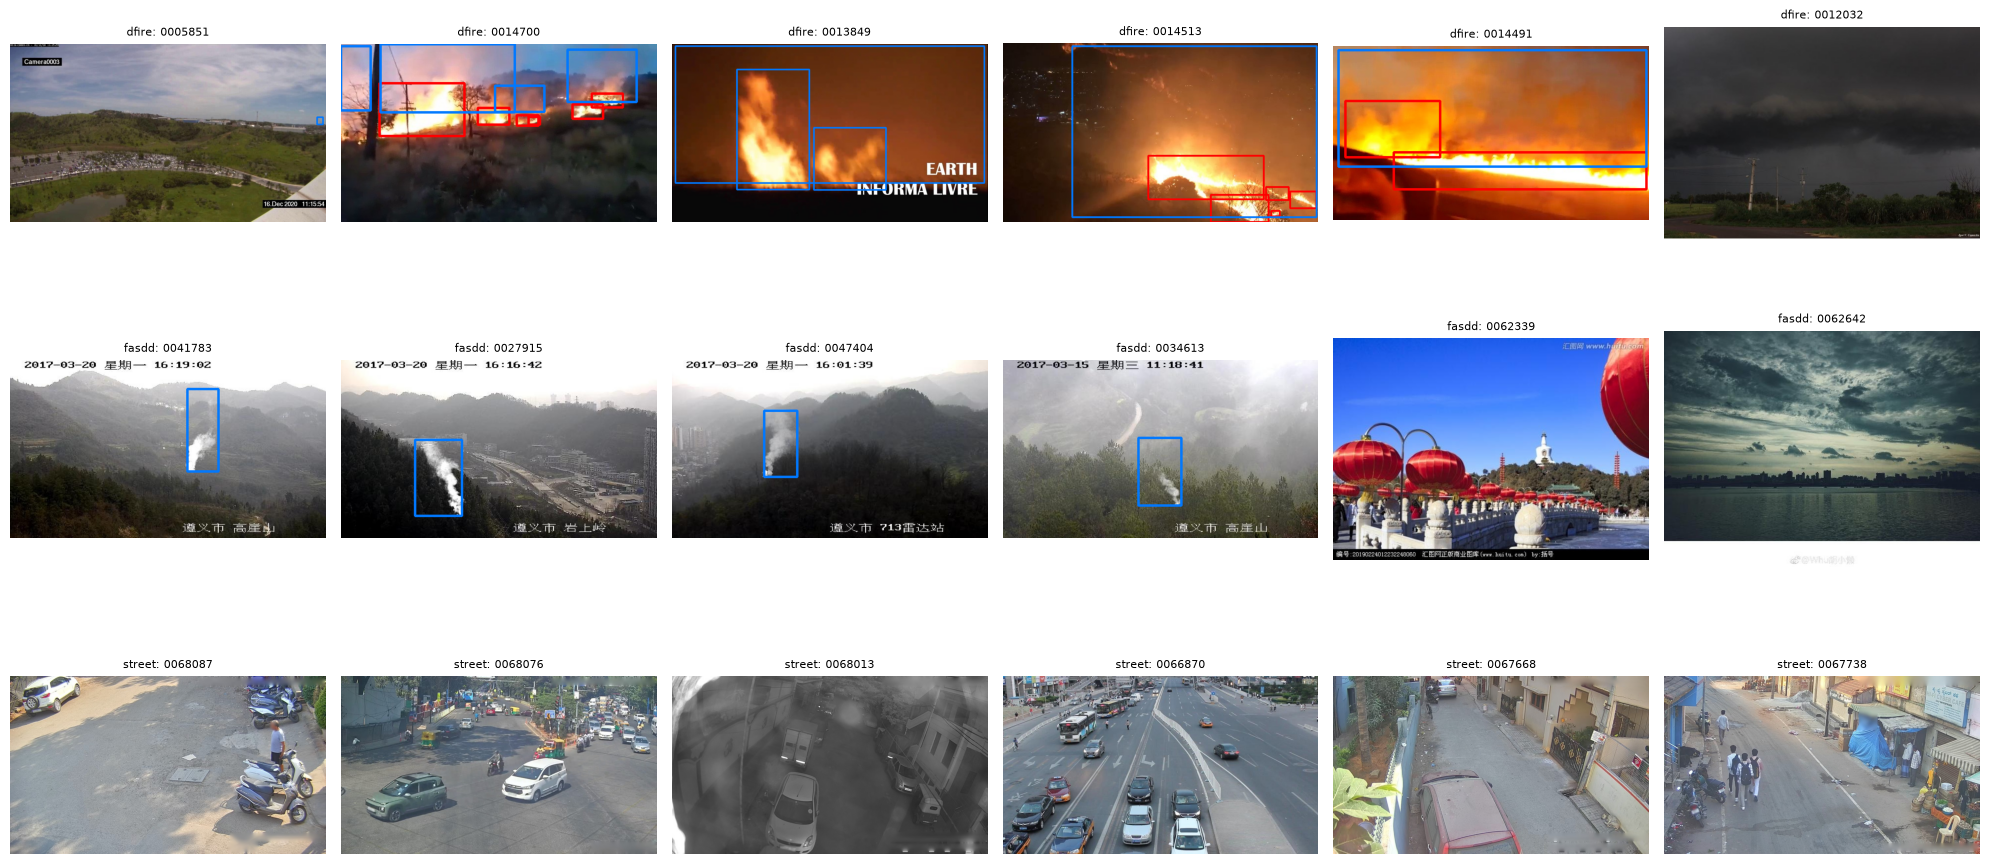

In [27]:
import cv2, matplotlib.pyplot as plt
man = pd.read_csv(DATASET_DIR / "manifest.csv")
srcs = sorted(man["source"].unique())
fig, axes = plt.subplots(len(srcs), 6, figsize=(20, 3.4 * len(srcs)), squeeze=False)
for r, s in enumerate(srcs):
    sub = man[(man.source == s) & (man.split == "train")]
    pos = sub[(sub.n_fire + sub.n_smoke) > 0]
    pick = pd.concat([pos.sample(min(4, len(pos)), random_state=1),
                      sub.sample(min(6, len(sub)), random_state=2)]).drop_duplicates().head(6)
    for c in range(6):
        ax = axes[r][c]; ax.axis("off")
        if c >= len(pick): continue
        name = pick.iloc[c]["name"]
        im = cv2.imread(str(DATASET_DIR / "images" / "train" / f"{name}.jpg"))
        h, w = im.shape[:2]
        cls, boxes = read_yolo_label(DATASET_DIR / "labels" / "train" / f"{name}.txt", w, h)
        for k, b in zip(cls, boxes):
            col = (0, 0, 255) if k == 0 else (255, 120, 0)
            cv2.rectangle(im, tuple(map(int, b[:2])), tuple(map(int, b[2:])), col, max(2, w // 200))
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(f"{s}: {name[-7:]}", fontsize=8)
plt.tight_layout(); plt.show()

## 28. Train the initial detector

Trains YOLO26-m on the prepared data, starting from pretrained weights, and records its selected checkpoint.


New https://pypi.org/project/ultralytics/8.4.197 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.194 🚀 Python-3.11.5 torch-2.15.0+cu132 CUDA:0 (NVIDIA A100 80GB PCIe, 81175MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=3, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/root/work/dataset/data.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.005, hsv_s=0.6, hsv_v=0.45, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.05, mode=train, model=yolo26m

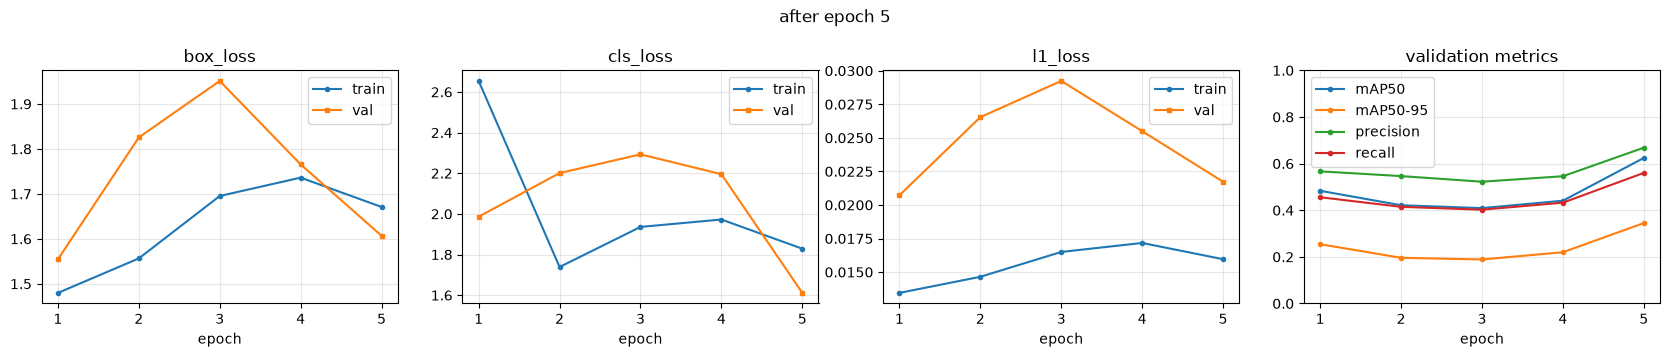


      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       6/25      53.9G      1.618      1.728    0.01537         88        800: 100% ━━━━━━━━━━━━ 656/656 2.4it/s 4:340.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 2.6it/s 11.4s0.4s
                   all       3829       5275      0.664      0.576      0.638      0.362

[######-------------------]  24.1% | epoch 6/25 | elapsed 28m52s | ETA 1h31m07s | epoch time 4m46s
   loss        box_loss   cls_loss    l1_loss      total
   train         1.6176     1.7282     0.0154     3.3612
   val           1.5325     1.5771     0.0204     3.1300
   val metrics: P=0.664  R=0.576  mAP50=0.638  mAP50-95=0.362  | best fitness so far=0.3624

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       7/25      53.9G      1.584      1.661    0.01489        102        800: 100% ━━━━━━━━━━━━ 656/656 2.4it/s 4:340.3ss
            

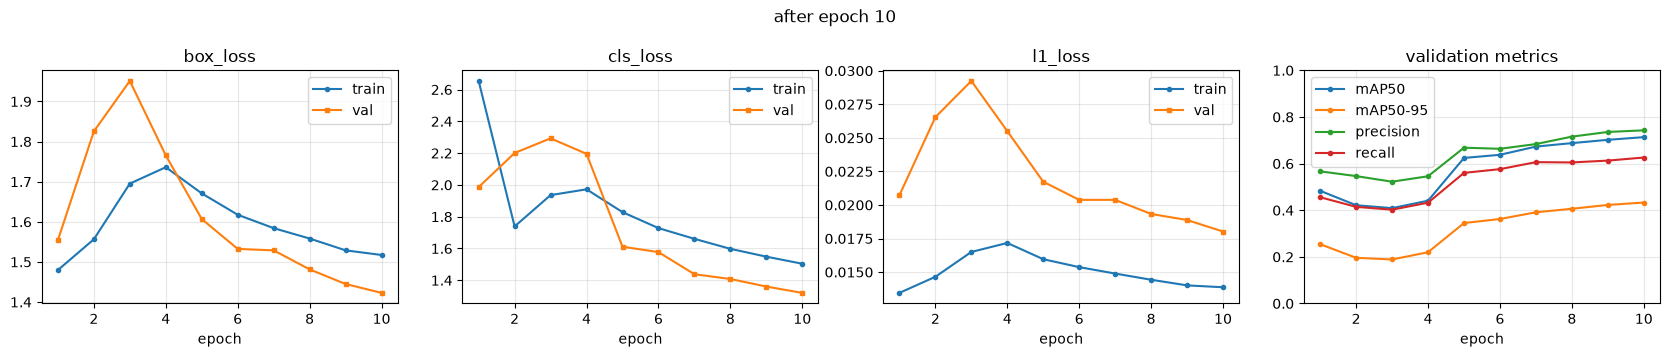


      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      11/26      53.9G      1.491      1.477    0.01359        139        800: 100% ━━━━━━━━━━━━ 656/656 2.4it/s 4:340.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 2.7it/s 11.0s0.4s
                   all       3829       5275      0.743      0.636      0.723      0.445

[##########---------------]  44.0% | epoch 11/26 | elapsed 52m44s | ETA 1h07m15s | epoch time 4m46s
   loss        box_loss   cls_loss    l1_loss      total
   train         1.4913     1.4768     0.0136     2.9817
   val           1.3967     1.2802     0.0177     2.6946
   val metrics: P=0.743  R=0.636  mAP50=0.723  mAP50-95=0.445  | best fitness so far=0.4448

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      12/26        54G      1.467      1.435    0.01326         62        800: 100% ━━━━━━━━━━━━ 656/656 2.4it/s 4:340.3ss
           

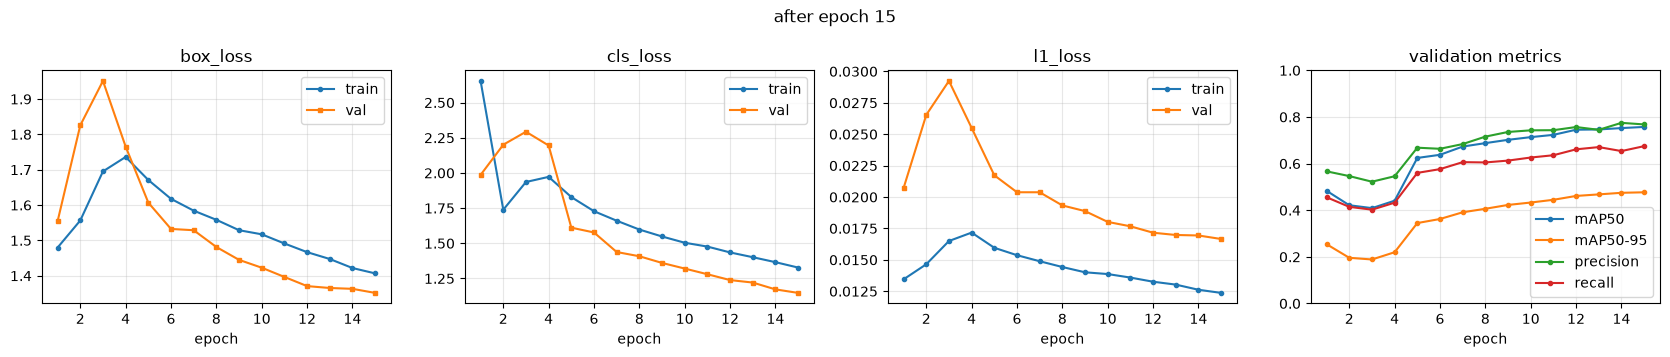


      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      16/26        54G      1.391      1.292    0.01221         96        800: 100% ━━━━━━━━━━━━ 656/656 2.4it/s 4:340.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 2.8it/s 10.8s0.4s
                   all       3829       5275      0.771      0.664      0.759      0.483

[###############----------]  63.8% | epoch 16/26 | elapsed 1h16m35s | ETA 43m24s | epoch time 4m46s
   loss        box_loss   cls_loss    l1_loss      total
   train         1.3908     1.2916     0.0122     2.6946
   val           1.3323     1.1499     0.0163     2.4985
   val metrics: P=0.771  R=0.664  mAP50=0.759  mAP50-95=0.483  | best fitness so far=0.4831

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      17/26        54G      1.365      1.243     0.0118        146        800: 100% ━━━━━━━━━━━━ 656/656 2.4it/s 4:340.3ss
           

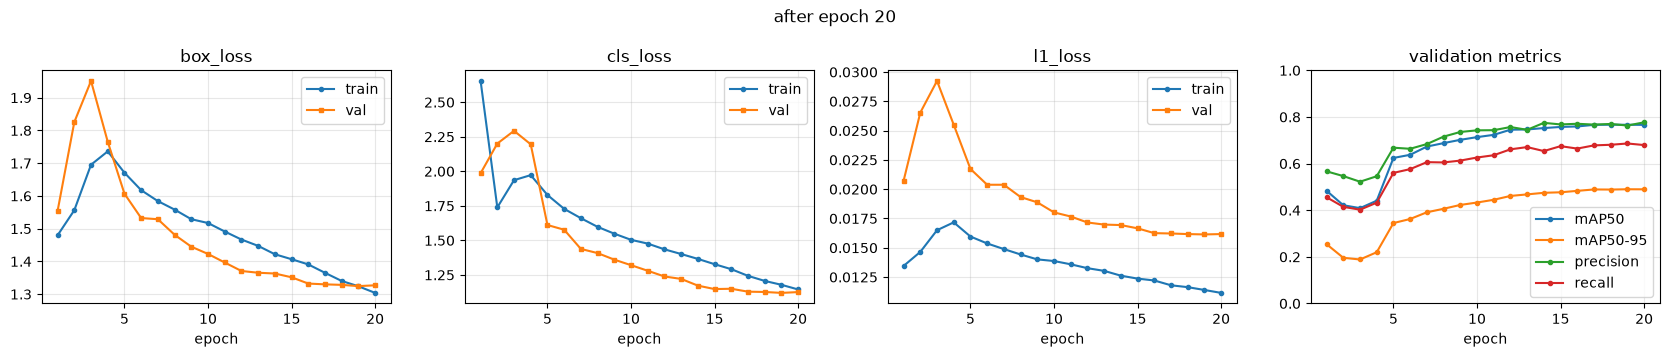


      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      21/26        54G      1.285      1.118    0.01088         93        800: 100% ━━━━━━━━━━━━ 656/656 2.4it/s 4:340.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 2.8it/s 10.7s0.4s
                   all       3829       5275      0.777      0.681      0.766      0.489

[####################-----]  83.7% | epoch 21/26 | elapsed 1h40m25s | ETA 19m34s | epoch time 4m46s
   loss        box_loss   cls_loss    l1_loss      total
   train         1.2846     1.1181     0.0109     2.4136
   val           1.3262     1.1293     0.0161     2.4716
   val metrics: P=0.777  R=0.681  mAP50=0.766  mAP50-95=0.489  | best fitness so far=0.4900

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      22/26        54G      1.273      1.092    0.01076         92        800: 100% ━━━━━━━━━━━━ 656/656 2.4it/s 4:340.3ss
           

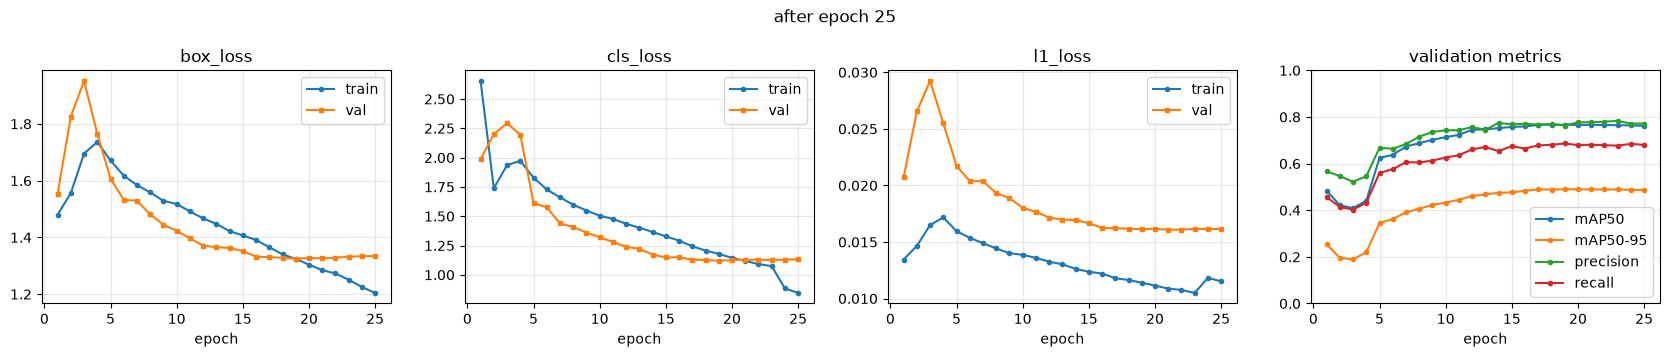


      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      26/26        54G      1.191      0.813    0.01136         71        800: 10% ━─────────── 72/656 2.4it/s 30.6s<4:02
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 2.8it/s 10.7s0.4s
                   all       3829       5275      0.773       0.68      0.763      0.487

[#########################] 100.0% | epoch 26/26 | elapsed 2h00m11s | ETA 0m00s | epoch time 0m42s
   loss        box_loss   cls_loss    l1_loss      total
   train         1.1913     0.8126     0.0114     2.0153
   val           1.3343     1.1331     0.0162     2.4836
   val metrics: P=0.773  R=0.680  mAP50=0.763  mAP50-95=0.487  | best fitness so far=0.4900

26 epochs completed in 2.003 hours.
Optimizer stripped from /__modal/volumes/vo-E7ioX3szW0Ac4txUqjOrhY/runs/det_v1/weights/last.pt, 44.0MB
Optimizer stripped from /__modal/volumes/vo-E7ioX3szW0Ac4txUqjOrhY/runs/det

In [27]:
t0 = time.time()
best_v1, dir_v1 = train_det.train_detector(
    DATA_YAML, RUNS_DIR, f"det_v1{SFX}", model=DET_MODEL, hours=DET_HOURS_V1, epochs=300, imgsz=IMGSZ,
    batch=DET_BATCH, workers=WORKERS, device=DEVICE, plot_every=5, **TRAIN_CFG["detector"]["augment"])
print("best v1 weights:", best_v1, "| wall time", fmt_secs(time.time() - t0))

## 29. Inspect the initial detector

Plots the detector training and validation curves and saves the validation summary.


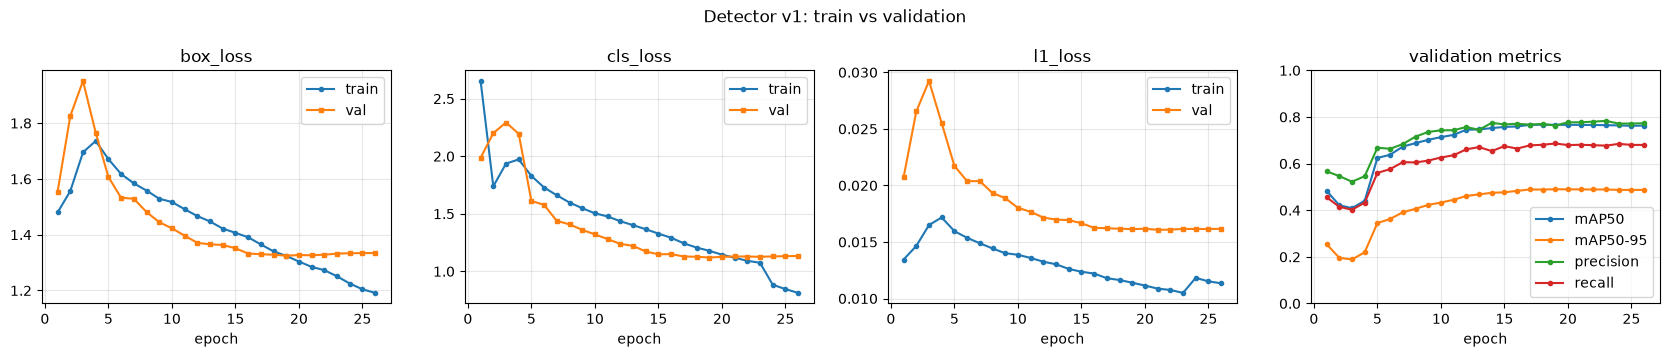

{'metrics/precision(B)': 0.773, 'metrics/recall(B)': 0.6801, 'metrics/mAP50(B)': 0.7629, 'metrics/mAP50-95(B)': 0.4874, 'val/box_loss': 1.3343, 'val/cls_loss': 1.1331, 'val/l1_loss': 0.0162}
   eval val: 2,048/3,829 (53%) elapsed 0m11s ETA 0m10s
   eval val: 3,829/3,829 (100%) elapsed 0m21s ETA 0m00s

Image-level results on 'val' (3,829 images)
  conf  fire recall  smoke recall  FP on negatives
  0.10        0.983         0.966            0.027
  0.15        0.977         0.958            0.017
  0.20        0.974         0.944            0.015
  0.25        0.963         0.925            0.014
  0.30        0.952         0.902            0.011
  0.40        0.908         0.850            0.007
  0.50        0.832         0.774            0.005


In [28]:
train_det.plot_detector_curves(Path(dir_v1) / "results.csv", out_png=PROJECT_DIR / "reports" / "detector_v1_curves.png",
                               title="Detector v1: train vs validation")
rows = train_det.read_results_csv(Path(dir_v1) / "results.csv")
last = rows[-1]
print({k: round(v, 4) for k, v in last.items() if k.startswith(("metrics/", "val/"))})
img_eval_v1 = mining.image_level_eval(best_v1, DATASET_DIR, split="val", device=DEVICE, imgsz=IMGSZ)
save_metric("detector_v1", {"weights": str(best_v1), "epochs": len(rows), "final_epoch": last, "image_level_val": img_eval_v1})

## 30. Mine hard negatives and train detector v2

Mines false detections on fire-free inputs, then uses the mined examples for the second detector stage when available.


   false-alarm test: 396/396 (100%) elapsed 0m51s ETA 0m00s
detector v1, false detections on held-out fire-free street frames: {'0.1': 0.018, '0.2': 0.008, '0.25': 0.003, '0.3': 0.003, '0.4': 0.0, '0.5': 0.0}
   mining street frames: 800/800 (100%) elapsed 1m42s ETA 0m00s
Mined 1 hard-negative images out of 800 fire-free frames
New https://pypi.org/project/ultralytics/8.4.197 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.194 🚀 Python-3.11.5 torch-2.15.0+cu132 CUDA:0 (NVIDIA A100 80GB PCIe, 81175MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/root/work/dataset/data_v2.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1

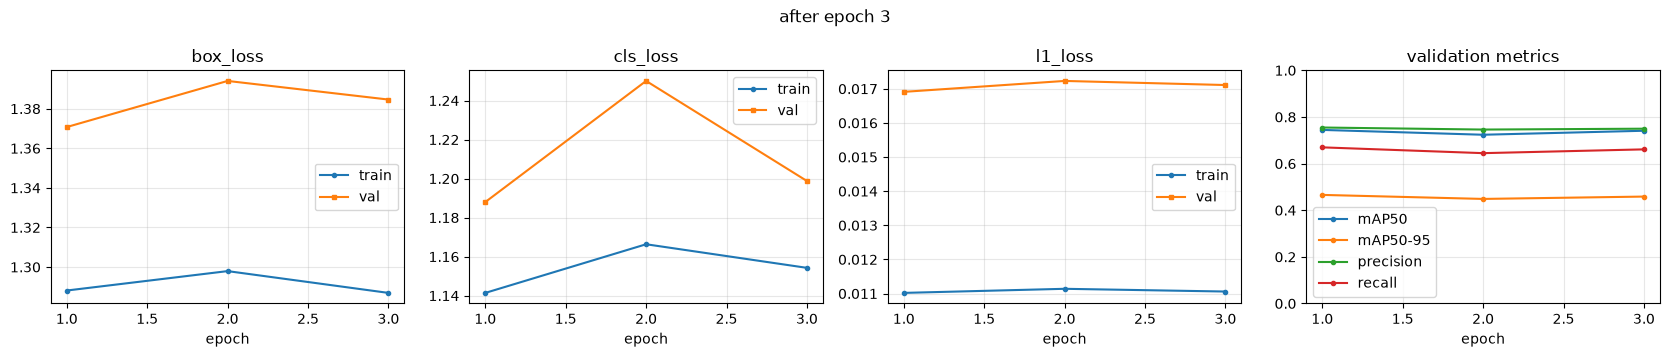


      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/10      53.9G      1.285      1.137    0.01104         88        800: 100% ━━━━━━━━━━━━ 656/656 2.5it/s 4:240.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 2.8it/s 10.6s0.4s
                   all       3829       5275      0.759      0.659      0.744      0.463

[##########---------------]  41.2% | epoch 4/10 | elapsed 18m33s | ETA 26m26s | epoch time 4m36s
   loss        box_loss   cls_loss    l1_loss      total
   train         1.2846     1.1369     0.0110     2.4325
   val           1.3771     1.2090     0.0170     2.6032
   val metrics: P=0.759  R=0.659  mAP50=0.744  mAP50-95=0.463  | best fitness so far=0.4657

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       5/10      53.9G      1.282      1.113    0.01092         74        800: 100% ━━━━━━━━━━━━ 656/656 2.5it/s 4:240.3ss
              

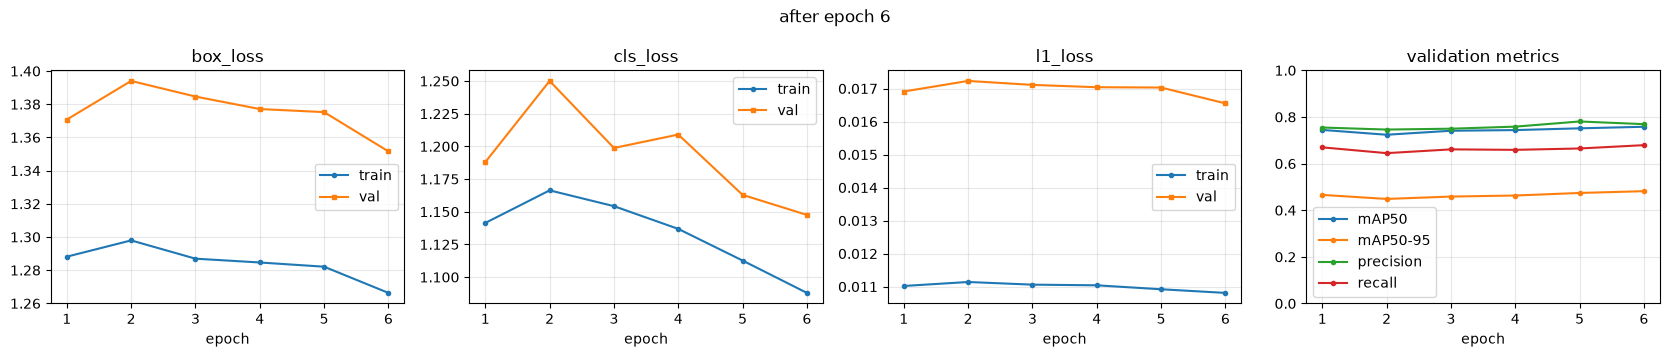


      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       7/10      53.9G      1.255      1.063    0.01058        103        800: 100% ━━━━━━━━━━━━ 656/656 2.5it/s 4:240.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 2.8it/s 10.6s0.4s
                   all       3829       5275      0.756      0.678      0.755      0.481

[#################--------]  71.9% | epoch 7/10 | elapsed 32m21s | ETA 12m38s | epoch time 4m36s
   loss        box_loss   cls_loss    l1_loss      total
   train         1.2546     1.0630     0.0106     2.3282
   val           1.3572     1.1514     0.0166     2.5252
   val metrics: P=0.756  R=0.678  mAP50=0.755  mAP50-95=0.481  | best fitness so far=0.4817

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       8/10      53.8G      1.247      1.047    0.01041        126        800: 100% ━━━━━━━━━━━━ 656/656 2.5it/s 4:240.3ss
              

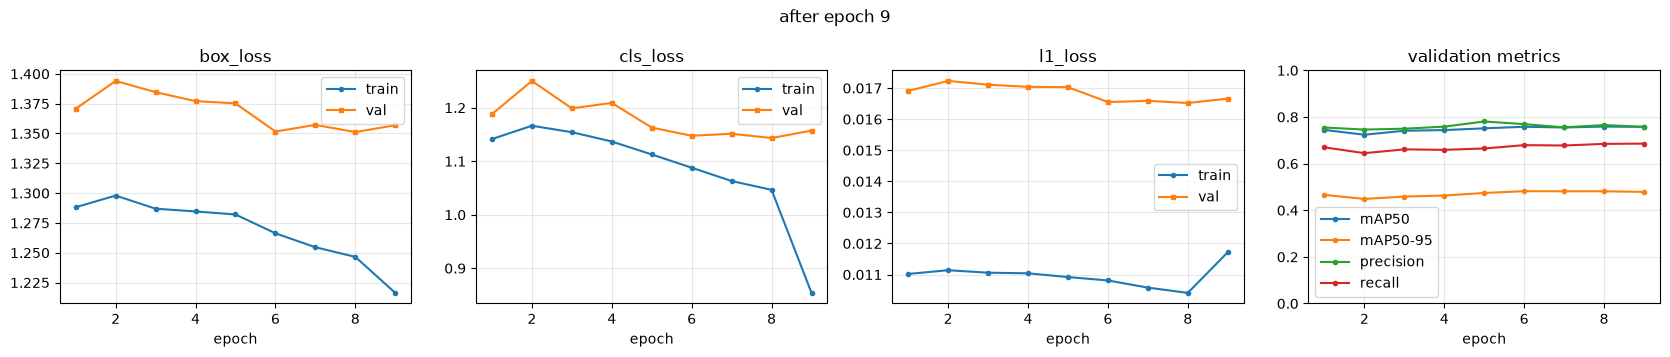


      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      10/10      53.8G      1.192     0.8183    0.01136         87        800: 78% ━━━━━━━━━─── 515/656 2.5it/s 3:26<56.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 2.8it/s 10.6s0.4s
                   all       3829       5275      0.764      0.684      0.761      0.482

[#########################] 100.0% | epoch 10/10 | elapsed 45m11s | ETA 0m00s | epoch time 3m37s
   loss        box_loss   cls_loss    l1_loss      total
   train         1.1921     0.8183     0.0114     2.0217
   val           1.3565     1.1495     0.0166     2.5226
   val metrics: P=0.764  R=0.684  mAP50=0.761  mAP50-95=0.482  | best fitness so far=0.4824

10 epochs completed in 0.753 hours.
Optimizer stripped from /__modal/volumes/vo-E7ioX3szW0Ac4txUqjOrhY/runs/det_v2/weights/last.pt, 44.0MB
Optimizer stripped from /__modal/volumes/vo-E7ioX3szW0Ac4txUqjOrhY/runs/det_

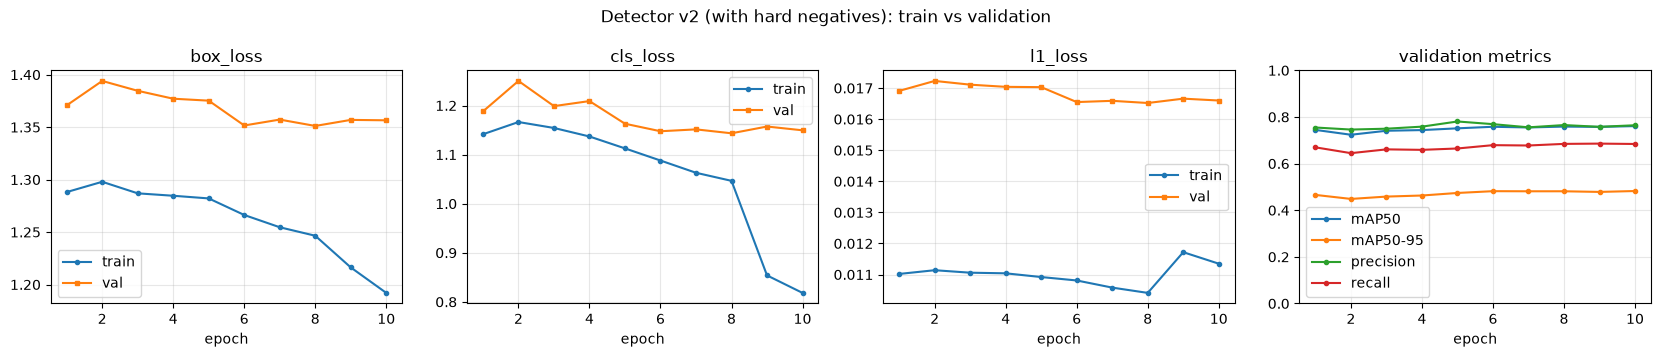

val mAP50: v1 0.767 | v2 0.761
   false-alarm test: 396/396 (100%) elapsed 0m01s ETA 0m00s
final detector, false detections on the same frames: {'0.1': 0.023, '0.2': 0.008, '0.25': 0.003, '0.3': 0.003, '0.4': 0.0, '0.5': 0.0}
   eval test: 1,958/1,958 (100%) elapsed 0m09s ETA 0m00s

Image-level results on 'test' (1,958 images)
  conf  fire recall  smoke recall  FP on negatives
  0.10        0.983         0.934            0.040
  0.15        0.975         0.921            0.031
  0.20        0.967         0.910            0.030
  0.25        0.957         0.885            0.027
  0.30        0.942         0.860            0.024
  0.40        0.896         0.804            0.014
  0.50        0.843         0.745            0.009
final detector: /__modal/volumes/vo-E7ioX3szW0Ac4txUqjOrhY/runs/det_v2/weights/best.pt -> weights/detector.pt


In [29]:
normal_dirs = [RAW_DIR / d for d in TRAIN_CFG["mining"]["video_dirs"]]
n_videos = sum(len(list_files(d, VID_EXTS)) for d in normal_dirs)
street = {}
if AUTO_STREET_NEGATIVES:
    st = TRAIN_CFG["data"]["street"]
    street = data_prep.get_street_frames(RAW_DIR, st["n_train"], st["n_mine"], st["n_test"])
mine_imgs, test_imgs = street.get("mine"), street.get("test")
mined_dir = DATASET_DIR / "images" / "mined"
final_det, dir_v2 = best_v1, None

fp_v1 = mining.street_fp_rate(best_v1, test_imgs, device=DEVICE, imgsz=IMGSZ) if test_imgs else None
if fp_v1:
    print("detector v1, false detections on held-out fire-free street frames:", {k: round(v, 3) for k, v in fp_v1["fp_rate"].items()})

if (n_videos or mine_imgs) and DET_HOURS_V2 > 0:
    if not (mined_dir.exists() and any(mined_dir.iterdir())):
        m = TRAIN_CFG["mining"]
        if n_videos:
            mining.mine_video_false_positives(best_v1, normal_dirs, DATASET_DIR, every_s=m["every_s"], conf=m["conf"],
                                              max_per_video=m["max_per_video"], repeat=m["repeat"], device=DEVICE,
                                              imgsz=IMGSZ, max_side=MAX_SIDE, crop_dir=CROPS_DIR)
        if mine_imgs:
            mining.mine_image_false_positives(best_v1, mine_imgs, DATASET_DIR, conf=m["conf"], repeat=m["repeat"],
                                              device=DEVICE, imgsz=IMGSZ, max_side=MAX_SIDE, crop_dir=CROPS_DIR)
    n_mined = len(list_files(mined_dir, IMG_EXTS))
    save_metric("mining", {"normal_videos": n_videos, "street_mining_frames": bool(mine_imgs), "mined_frames_incl_copies": n_mined})
    if n_mined:
        data_v2 = data_prep.write_data_yaml(DATASET_DIR, extra_train_dirs=["images/mined"])
        aug = dict(TRAIN_CFG["detector"]["augment"], close_mosaic=2)
        best_v2, dir_v2 = train_det.train_detector(
            data_v2, RUNS_DIR, f"det_v2{SFX}", model=str(best_v1), hours=DET_HOURS_V2, epochs=100, imgsz=IMGSZ,
            batch=DET_BATCH, workers=WORKERS, device=DEVICE, plot_every=3, optimizer="SGD",
            lr0=TRAIN_CFG["detector"]["lr0_v2"], lrf=0.1, warmup_epochs=0.5, **aug)
        train_det.plot_detector_curves(Path(dir_v2) / "results.csv", out_png=PROJECT_DIR / "reports" / "detector_v2_curves.png",
                                       title="Detector v2 (with hard negatives): train vs validation")
        map_v1 = max(r.get("metrics/mAP50(B)", 0) for r in train_det.read_results_csv(Path(dir_v1) / "results.csv"))
        map_v2 = max(r.get("metrics/mAP50(B)", 0) for r in train_det.read_results_csv(Path(dir_v2) / "results.csv"))
        print(f"val mAP50: v1 {map_v1:.3f} | v2 {map_v2:.3f}")
        final_det = best_v2 if map_v2 >= map_v1 - 0.02 else best_v1
    else:
        print("The detector made no mistakes on the fire-free frames - keeping v1.")
else:
    print("Nothing to mine (no street frames, no normal videos, or DET_HOURS_V2 = 0) - skipping; final detector = v1")
shutil.copy(final_det, PROJECT_DIR / "weights" / "detector.pt")

fp_final = mining.street_fp_rate(PROJECT_DIR / "weights" / "detector.pt", test_imgs, device=DEVICE, imgsz=IMGSZ) if test_imgs else None
if fp_v1 and fp_final:
    print("final detector, false detections on the same frames:", {k: round(v, 3) for k, v in fp_final["fp_rate"].items()})
    save_metric("street_fp_test", {"v1": fp_v1, "final": fp_final})
img_eval_final = mining.image_level_eval(PROJECT_DIR / "weights" / "detector.pt", DATASET_DIR, split="test",
                                         device=DEVICE, imgsz=IMGSZ)
save_metric("detector_final", {"source_run": str(final_det), "image_level_test": img_eval_final})
print("final detector:", final_det, "-> weights/detector.pt")

## 31. Evaluate the held-out image split

Computes detector-only precision, recall, and mAP on the test split.


In [30]:
from ultralytics import YOLO
res = YOLO(str(PROJECT_DIR / "weights" / "detector.pt")).val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=32,
                                                             device=DEVICE, plots=False, verbose=True)
test_map = {"mAP50": float(res.box.map50), "mAP50-95": float(res.box.map), "precision": float(res.box.mp),
            "recall": float(res.box.mr),
            "per_class_mAP50": {CLASS_NAMES[i]: float(v) for i, v in enumerate(res.box.ap50)}}
save_metric("detector_test_map", test_map)
print(test_map)

Ultralytics 8.4.194 🚀 Python-3.11.5 torch-2.15.0+cu132 CUDA:0 (NVIDIA A100 80GB PCIe, 81175MiB)
YOLO26m summary (fused): 130 layers, 20,350,994 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1032.5±711.0 MB/s, size: 49.5 KB)
val: Scanning /root/work/dataset/labels/test... 1958 images, 807 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1958/1958 2.4Kit/s 0.8s0.0s
val: New cache created: /root/work/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 62/62 7.0it/s 8.9s0.1ss
                   all       1958       2622      0.745      0.663       0.72       0.44
                  fire        635       1500      0.714      0.654       0.72      0.409
                 smoke        954       1122      0.776      0.671       0.72      0.472
Speed: 0.2ms preprocess, 2.7ms inference, 0.0ms loss, 0.4ms postprocess per image
{'mAP50': 0.719529571205892, 'mAP50-95': 0.44045506478941,

## 32. Prepare verifier crops

Extracts and labels fire, smoke, and background crops using detector proposals.


In [31]:
if not (CROPS_DIR / "crop_stats.json").exists():
    v = TRAIN_CFG["verifier"]
    mining.build_verifier_dataset(PROJECT_DIR / "weights" / "detector.pt", DATASET_DIR, CROPS_DIR, conf=v["mine_conf"],
                                  device=DEVICE, imgsz=IMGSZ, pad=v["pad"], max_images=v["max_images"], caps=v["caps"])
crop_stats = json.loads((CROPS_DIR / "crop_stats.json").read_text())
save_metric("verifier_crops", crop_stats)
print(crop_stats)

   crops train: 2,048/30,000 (7%) elapsed 0m16s ETA 3m38s
   crops train: 4,032/30,000 (13%) elapsed 0m30s ETA 3m18s
   crops train: 6,016/30,000 (20%) elapsed 0m45s ETA 3m02s
   crops train: 8,000/30,000 (27%) elapsed 1m00s ETA 2m46s
   crops train: 10,048/30,000 (33%) elapsed 1m15s ETA 2m30s
   crops train: 12,032/30,000 (40%) elapsed 1m29s ETA 2m14s
   crops train: 14,016/30,000 (47%) elapsed 1m43s ETA 1m57s
   crops train: 16,000/30,000 (53%) elapsed 1m56s ETA 1m42s
   crops train: 18,048/30,000 (60%) elapsed 2m07s ETA 1m24s
   crops train: 20,032/30,000 (67%) elapsed 2m17s ETA 1m08s
   crops train: 22,016/30,000 (73%) elapsed 2m27s ETA 0m53s
   crops train: 24,000/30,000 (80%) elapsed 2m37s ETA 0m39s
   crops train: 26,048/30,000 (87%) elapsed 2m47s ETA 0m25s
   crops train: 28,032/30,000 (93%) elapsed 2m57s ETA 0m12s
   crops train: 30,000/30,000 (100%) elapsed 3m07s ETA 0m00s
Verifier crops [train]: {'fire': 15000, 'smoke': 15000, 'not_fire': 10392}
   crops val: 2,048/3,829 (53

## 33. Train the crop verifier

Fits EfficientNet-B0 on the crop dataset and records the selected verifier checkpoint and training curves.


/usr/local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Verifier classes ['fire', 'not_fire', 'smoke'] | train {'fire': 15000, 'not_fire': 10392, 'smoke': 15000} | val 5,615 crops
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 196MB/s]
                                                                  

[###----------------------]  12.5% | epoch 1/8 | elapsed 0m47s | ETA 5m31s
   train loss 0.6559 acc 0.734 | val loss 0.4668 acc 0.786 | val: fire/smoke kept 0.880, false positives rejected 0.620 | per-class recall {fire: 0.741, not_fire: 0.641, smoke: 0.948}
   saved best verifier -> /root/lab/volume/runs/verifier/verifier.pt


[######-------------------]  25.0% | epoch 2/8 | elapsed 1m31s | ETA 4m34s
   train loss 0.5382 acc 0.801 | val loss 0.4415 acc 0.797 | val: fire/smoke kept 0.848, false positives rejected 0.719 | per-class recall {fire: 0.740, not_fire: 0.734, smoke: 0.905}
   saved best verifier -> /root/lab/volume/runs/verifier/verifier.pt


[#########----------------]  37.5% | epoch 3/8 | elapsed 2m15s | ETA 3m46s
   train loss 0.5049 acc 0.818 | val loss 0.4411 acc 0.796 | val: fire/smoke kept 0.863, false positives rejected 0.668 | per-class recall {fire: 0.754, not_fire: 0.685, smoke: 0.927}
   saved best verifier -> /root/lab/volume/runs/verifier/verifier.pt


[############-------------]  50.0% | epoch 4/8 | elapsed 3m00s | ETA 3m00s
   train loss 0.4744 acc 0.838 | val loss 0.4538 acc 0.792 | val: fire/smoke kept 0.879, false positives rejected 0.626 | per-class recall {fire: 0.757, not_fire: 0.632, smoke: 0.957}


[###############----------]  62.5% | epoch 5/8 | elapsed 3m44s | ETA 2m14s
   train loss 0.4364 acc 0.860 | val loss 0.4705 acc 0.789 | val: fire/smoke kept 0.849, false positives rejected 0.682 | per-class recall {fire: 0.719, not_fire: 0.687, smoke: 0.941}


[##################-------]  75.0% | epoch 6/8 | elapsed 4m28s | ETA 1m29s
   train loss 0.3964 acc 0.884 | val loss 0.4737 acc 0.796 | val: fire/smoke kept 0.875, false positives rejected 0.648 | per-class recall {fire: 0.757, not_fire: 0.658, smoke: 0.946}


[#####################----]  87.5% | epoch 7/8 | elapsed 5m12s | ETA 0m44s
   train loss 0.3610 acc 0.906 | val loss 0.4904 acc 0.794 | val: fire/smoke kept 0.876, false positives rejected 0.638 | per-class recall {fire: 0.765, not_fire: 0.642, smoke: 0.947}


[#########################] 100.0% | epoch 8/8 | elapsed 5m57s | ETA 0m00s
   train loss 0.3438 acc 0.916 | val loss 0.4912 acc 0.796 | val: fire/smoke kept 0.880, false positives rejected 0.633 | per-class recall {fire: 0.784, not_fire: 0.638, smoke: 0.933}


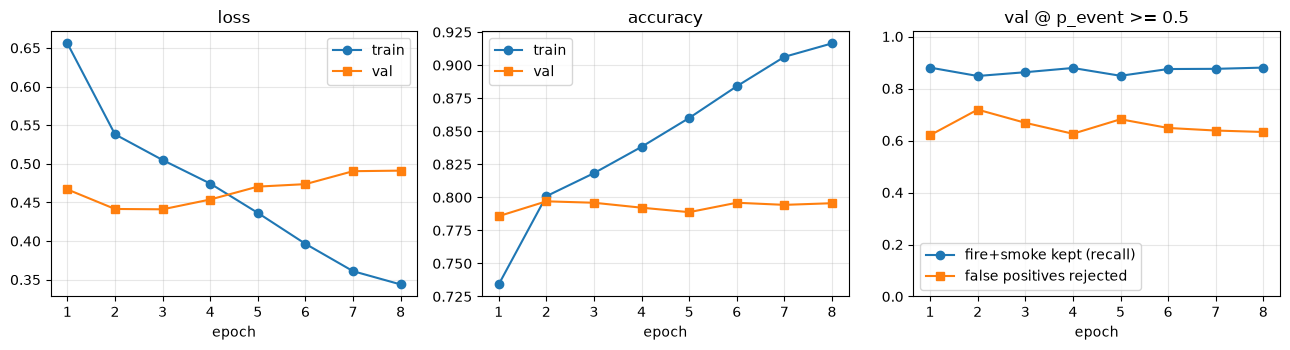

Verifier training done in 5m57s
verifier -> weights/verifier.pt | best epoch: 3 | val acc 0.796


In [32]:
v = TRAIN_CFG["verifier"]
ver_out = RUNS_DIR / f"verifier{SFX}" / "verifier.pt"
hist_file = ver_out.with_suffix(".history.json")
if ver_out.exists() and hist_file.exists():
    print(f"verifier already trained - delete {ver_out.parent} to retrain")
    history = json.loads(hist_file.read_text())
    tv.plot_verifier_curves(history)
else:
    history = tv.train_verifier(CROPS_DIR, ver_out, epochs=v["epochs"], batch=v["batch"], lr=v["lr"], imgsz=v["imgsz"],
                                workers=WORKERS, device=v["device"], pad=v["pad"], show_plots=True)
shutil.copy(ver_out, PROJECT_DIR / "weights" / "verifier.pt")
shutil.copy(ver_out.with_suffix(".curves.png"), PROJECT_DIR / "reports" / "verifier_curves.png")
best_h = min(history, key=lambda h: h["val_loss"])
save_metric("verifier", {"best_epoch": best_h, "history": history})
print("verifier -> weights/verifier.pt | best epoch:", best_h["epoch"], "| val acc", round(best_h["val_acc"], 3))

## 34. Run the complete video pipeline

Runs the detector, verifier, and temporal alarm logic through `infer.py` and displays sample output records.


In [28]:
cand = list_files(EVAL_DIR / "fire", VID_EXTS) + list_files(EVAL_DIR / "smoke", VID_EXTS) + \
       list_files(EVAL_DIR / "normal", VID_EXTS) + list_files(RAW_DIR / "normal_videos", VID_EXTS)
if not cand:
    print("No video on the volume yet - upload one to raw/eval_videos/fire/ to see an alarm.")
else:
    demo = cand[0]
    out_demo = WORK_DIR / "demo_results"
    dev = "cuda:0" if DEVICE != "cpu" else "cpu"
    run(f'{sys.executable} infer.py --source "{demo}" --config config.yaml --output-dir "{out_demo}" --device {dev} --no-display --save-video',
        cwd=PROJECT_DIR)
    print("\n--- run_summary.json ---");  print((out_demo / "run_summary.json").read_text()[:1500])
    print("\n--- alarms.jsonl ---");      print((out_demo / "alarms.jsonl").read_text() or "(no alarm)")
    print("\n--- predictions.jsonl (first 3 frames with detections) ---")
    lines = [l for l in (out_demo / "predictions.jsonl").read_text().splitlines() if '"predictions": [{' in l][:3]
    print("\n".join(lines) or "(no detections)")

$ /usr/local/bin/python infer.py --source "/root/lab/volume/raw/eval_videos/fire/fs_fire_posVideo1.868.avi" --config config.yaml --output-dir "/root/work/demo_results" --device cuda:0 --no-display --save-video
Processing /root/lab/volume/raw/eval_videos/fire/fs_fire_posVideo1.868.avi ...
  ALARM FIRE at t=1.60s (frame 16, conf 0.71, onset 0.40s)
  ALARM SMOKE at t=3.60s (frame 36, conf 0.66, onset 1.80s)
  done: completed | read 293 | processed 147 | skipped 146 | alarms 2 | 5.4s
Status: completed | outputs in /root/work/demo_results

--- run_summary.json ---
{
  "status": "completed",
  "frames_read": 293,
  "frames_processed": 147,
  "frames_skipped": 146,
  "total_runtime_s": 9.233,
  "errors": [],
  "warnings": [],
  "alarms_raised": 2,
  "command": "infer.py --source /root/lab/volume/raw/eval_videos/fire/fs_fire_posVideo1.868.avi --config config.yaml --output-dir /root/work/demo_results --device cuda:0 --no-display --save-video",
  "config": "/__modal/volumes/vo-E7ioX3szW0Ac4txUqj

## 35. Evaluate the initial alarms

Scores the initial model pair on labeled videos and compares temporal settings when tuning is enabled.


In [29]:
import hashlib
cfg = load_yaml(PROJECT_DIR / "config.yaml")
if cfg["input"]["imgsz"] != IMGSZ:           # inference size must equal the training size
    cfg["input"]["imgsz"] = IMGSZ
    save_yaml(cfg, PROJECT_DIR / "config.yaml")
    print("config.yaml: input.imgsz set to", IMGSZ)
dev = "cuda:0" if DEVICE != "cpu" else "cpu"
pipe = inference.Pipeline(cfg, PROJECT_DIR, dev)
_wt = [PROJECT_DIR / "weights" / "detector.pt", PROJECT_DIR / "weights" / "verifier.pt"]
cache_dir = WORK_DIR / ("eval_cache_" + hashlib.md5("".join(f"{p.stat().st_size}{int(p.stat().st_mtime)}" for p in _wt).encode()).hexdigest()[:8])

test_imgs = None
if AUTO_STREET_NEGATIVES:
    _st = TRAIN_CFG["data"]["street"]
    test_imgs = data_prep.get_street_frames(RAW_DIR, _st["n_train"], _st["n_mine"], _st["n_test"]).get("test")
def street_report(tag):
    if test_imgs:
        r = ev.street_image_fp(pipe, test_imgs, cfg["verifier"]["min_prob"])
        print(f"false-alarm test on fire-free street frames ({tag}):", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in r.items()})
        save_metric("street_fp_pipeline", {**load_metrics().get("street_fp_pipeline", {}), tag: r})
street_report("before_tuning")

if not list(ev.list_eval_videos(EVAL_DIR)):
    print("No evaluation videos found in raw/eval_videos/{fire,smoke,normal}/ - keeping default alarm settings.")
else:
    res_before, per_video, data = ev.evaluate(pipe, cfg, EVAL_DIR, cache_dir, max_s=EVAL_MAX_SECONDS)
    print("\nWith current config:", json.dumps(res_before, indent=1))
    save_metric("video_eval_before_tuning", res_before)
    if TUNE_ALARMS:
        new_cfg, best, allres = ev.tune(*data, cfg)
        res_after = ev.score(*data, new_cfg["temporal"], new_cfg["verifier"]["min_prob"])
        print("\nAfter tuning:", json.dumps(res_after, indent=1))
        print("chosen:", json.dumps({"min_prob": best["min_prob"], "fire": best["fire"], "smoke": best["smoke"]}, indent=1))
        better = res_after["event_recall"] > res_before["event_recall"] or (
            res_after["event_recall"] == res_before["event_recall"] and res_after["event_recall"] > 0
            and res_after["false_alarms"] <= res_before["false_alarms"])
        if better:
            save_yaml(new_cfg, PROJECT_DIR / "config.yaml")
            cfg = new_cfg
            print("config.yaml updated with the tuned alarm settings")
        else:
            print("tuned settings were not better - config.yaml unchanged")
            res_after = res_before
        save_metric("video_eval_after_tuning", res_after)
    final_res, per_video, _ = ev.evaluate(pipe, cfg, EVAL_DIR, cache_dir, max_s=EVAL_MAX_SECONDS)
    save_metric("video_eval_final", {"summary": final_res, "per_video": per_video})
    display(pd.DataFrame(per_video))
street_report("final")

false-alarm test on fire-free street frames (before_tuning): {'n_images': 396, 'detector_rate': 0.008, 'after_verifier_rate': 0.0}
   [1/43] event  fs_fire_posVideo1.868.avi  (0m00s elapsed, ETA 0m00s)
   [2/43] event  fs_fire_posVideo10.869.avi  (0m00s elapsed, ETA 0m00s)
   [3/43] event  fs_fire_posVideo11.870.avi  (0m00s elapsed, ETA 0m00s)
   [4/43] event  fs_fire_posVideo2.871.avi  (0m00s elapsed, ETA 0m00s)
   [5/43] event  fs_fire_posVideo3.872.avi  (0m00s elapsed, ETA 0m00s)
   [6/43] event  fs_fire_posVideo4.873.avi  (0m00s elapsed, ETA 0m00s)
   [7/43] event  fs_fire_posVideo5.874.avi  (0m00s elapsed, ETA 0m00s)
   [8/43] event  fs_fire_posVideo6.875.avi  (0m00s elapsed, ETA 0m00s)
   [9/43] event  fs_fire_posVideo7.876.avi  (0m00s elapsed, ETA 0m00s)
   [10/43] event  fs_fire_posVideo8.877.avi  (0m00s elapsed, ETA 0m00s)
   [11/43] event  fs_fire_posVideo9.878.avi  (0m00s elapsed, ETA 0m00s)
   [12/43] event  fs_smoke_testpos01.817.avi  (0m00s elapsed, ETA 0m00s)
   [13/43] 

,video,kind,duration_s,alarms
0,fs_fire_posVideo1.868.avi,event,29.3,"[(fire, 2.6), (smoke, 2.8)]"
1,fs_fire_posVideo10.869.avi,event,7.8,"[(fire, 0.801), (smoke, 1.001)]"
2,fs_fire_posVideo11.870.avi,event,11.9,"[(fire, 2.2)]"
3,fs_fire_posVideo2.871.avi,event,17.0,"[(fire, 0.601)]"
4,fs_fire_posVideo3.872.avi,event,12.7,"[(fire, 0.601)]"
5,fs_fire_posVideo4.873.avi,event,55.2,"[(fire, 0.601)]"
6,fs_fire_posVideo5.874.avi,event,80.3,"[(fire, 0.601)]"
7,fs_fire_posVideo6.875.avi,event,25.8,"[(fire, 0.8), (smoke, 3.0)]"
8,fs_fire_posVideo7.876.avi,event,54.7,"[(fire, 31.0)]"
9,fs_fire_posVideo8.877.avi,event,17.1,"[(fire, 0.601)]"


false-alarm test on fire-free street frames (final): {'n_images': 396, 'detector_rate': 0.008, 'after_verifier_rate': 0.0}


## 36. Export the initial project artifacts

Builds the historical package and short verification examples. The export represents the initial model, not the final submitted checkpoints.


In [30]:
import cv2
def trim(src, dst, max_s=20):
    cap = cv2.VideoCapture(str(src)); fps = cap.get(cv2.CAP_PROP_FPS); fps = fps if 1 <= fps <= 240 else 25
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    s = min(1.0, 1280 / max(w, h)); size = (int(w * s) // 2 * 2, int(h * s) // 2 * 2)
    wr = cv2.VideoWriter(str(dst), cv2.VideoWriter_fourcc(*"mp4v"), fps, size)
    for _ in range(int(fps * max_s)):
        ok, f = cap.read()
        if not ok: break
        wr.write(cv2.resize(f, size) if s < 1 else f)
    cap.release(); wr.release()

ex_dir = PROJECT_DIR / "examples"
shutil.rmtree(ex_dir, ignore_errors=True); (ex_dir / "clips").mkdir(parents=True)
events = list_files(EVAL_DIR / "fire", VID_EXTS) + list_files(EVAL_DIR / "smoke", VID_EXTS)
normals = list_files(EVAL_DIR / "normal", VID_EXTS) or list_files(RAW_DIR / "normal_videos", VID_EXTS)
EXAMPLES = []
fe = load_metrics().get("video_eval_final", {}).get("per_video", [])
first_alarm = {p["video"]: p["alarms"][0][1] for p in fe if p["alarms"]}
if events:   # prefer an event clip whose first alarm comes early, so the trimmed clip still contains it
    events = sorted(events, key=lambda v: first_alarm.get(v.name, 1e9))
    trim(events[0], ex_dir / "clips" / "event_example.mp4"); EXAMPLES.append("event_example")
if normals:
    trim(normals[0], ex_dir / "clips" / "normal_example.mp4"); EXAMPLES.append("normal_example")
dev = "cuda:0" if DEVICE != "cpu" else "cpu"
for name in EXAMPLES:
    run(f"{sys.executable} infer.py --source examples/clips/{name}.mp4 --config config.yaml "
        f"--output-dir examples/expected_outputs/{name} --device {dev} --no-display", cwd=PROJECT_DIR)
    print(name, "alarms:", (ex_dir / "expected_outputs" / name / "alarms.jsonl").read_text() or "(none)")
if len(EXAMPLES) < 2:
    print("WARNING: add at least one fire clip to raw/eval_videos/fire/ and one normal clip to raw/eval_videos/normal/ "
          "and re-run this cell (README point 9 needs both).")

$ /usr/local/bin/python infer.py --source examples/clips/event_example.mp4 --config config.yaml --output-dir examples/expected_outputs/event_example --device cuda:0 --no-display
Processing examples/clips/event_example.mp4 ...
  ALARM FIRE at t=0.60s (frame 18, conf 0.90, onset 0.00s)
  done: completed | read 510 | processed 85 | skipped 425 | alarms 1 | 3.3s
Status: completed | outputs in /__modal/volumes/vo-E7ioX3szW0Ac4txUqjOrhY/fire_project/examples/expected_outputs/event_example
event_example alarms: {"source_id": "event_example", "event_id": "event_example-0001", "label": "fire", "decision_timestamp_s": 0.601, "decision_frame_index": 18, "confidence": 0.9001, "onset_timestamp_s": 0.0, "onset_frame_index": 0, "track_id": 1, "hits_in_window": 4, "bbox_xyxy": [110.3, 165.4, 166.7, 262.7]}

$ /usr/local/bin/python infer.py --source examples/clips/normal_example.mp4 --config config.yaml --output-dir examples/expected_outputs/normal_example --device cuda:0 --no-display
Processing exampl